# Reproducing every number in Chapter 4

This notebook reruns the whole study from a fixed random seed (42) and shows each table and figure used in Chapter 4.

* **Data:** two **simulated** portfolios of 6,000 loans each, produced by `src/data_generator.py`. They are modelled on the products and field types of a Nigerian commercial bank but contain no real customer records.
* **Design:** stratified 60/20/20 train / validation / test split; four models (Logistic Regression, Random Forest, LightGBM, XGBoost) under three imbalance treatments (none, class weighting, SMOTENC); 5-fold cross-validation on the training set; Platt calibration and the cost-minimising cutoff chosen on the validation set; the test set is used once.
* **Settings:** all in `src/config.py`.

Run time is a few minutes.

In [1]:
import os, sys, json
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, os.getcwd())
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option('display.max_columns', 30, 'display.width', 250)

## 1. Run the full experiment

In [2]:
from src import experiment
experiment.main()


=== Personal (salary earner) portfolio ===


 cross-validation ...


 fitting, calibrating, scoring ...


 SHAP ...



=== SME portfolio ===


 cross-validation ...


 fitting, calibrating, scoring ...


 SHAP ...



Done. Tables: results/thesis/tables  Figures: results/thesis/figures
{
 "numpy": "1.26.4",
 "pandas": "3.0.6",
 "sklearn": "1.9.1",
 "imblearn": "0.14.2",
 "xgboost": "2.1.4",
 "lightgbm": "4.7.0",
 "shap": "0.49.1",
 "scipy": "1.17.1",
 "matplotlib": "3.11.2"
}


In [3]:
print(json.dumps(json.load(open('results/thesis/run_info.json')), indent=2))

{
  "random_seed": 42,
  "split": "60/20/20 stratified train/validation/test",
  "cv_folds": 5,
  "bootstrap_resamples": 1000,
  "smote": "SMOTENC k=5",
  "data": "SIMULATED (src/data_generator.py, seed 42 / 52, 6,000 rows each)",
  "python": "3.11.18",
  "platform": "macOS-27.0.1-arm64-arm-64bit",
  "versions": {
    "numpy": "1.26.4",
    "pandas": "3.0.6",
    "sklearn": "1.9.1",
    "imblearn": "0.14.2",
    "xgboost": "2.1.4",
    "lightgbm": "4.7.0",
    "shap": "0.49.1",
    "scipy": "1.17.1",
    "matplotlib": "3.11.2"
  }
}


## 2. Tables

In [4]:
T = 'results/thesis/tables'
def show(name, title=None):
    display(Markdown(f"### {title or name}"))
    display(pd.read_csv(f"{T}/{name}.csv"))

for name in ['model_settings', 'cost_assumptions', 'personal_eda_numeric', 'retail_eda_numeric',
             'personal_eda_default_by_category', 'retail_eda_default_by_category', 'partitions',
             'cross_validation', 'personal_imbalance_ablation', 'retail_imbalance_ablation',
             'personal_model_scores_at_cutoff', 'retail_model_scores_at_cutoff',
             'personal_model_scores_at_050', 'retail_model_scores_at_050',
             'personal_delong', 'retail_delong', 'financial_savings', 'lgd_sensitivity',
             'personal_shap_ranking', 'retail_shap_ranking', 'retail_interest_rate_ablation',
             'personal_fairness', 'retail_fairness', 'deployed_models']:
    show(name)

### model_settings

,Model,"Hyperparameters (fixed, not tuned)",Feature scaling,Imbalance treatment (main),Also compared
0,Logistic Regression,"solver=lbfgs, max_iter=1000",StandardScaler,SMOTENC (k=5) on training data only,No resampling; class weighting
1,Random Forest,"n_estimators=200, max_depth=10, min_samples_sp...",None (raw units),SMOTENC (k=5) on training data only,No resampling; class weighting
2,LightGBM,"n_estimators=250, learning_rate=0.05, num_leav...",None (raw units),SMOTENC (k=5) on training data only,No resampling; class weighting
3,XGBoost,"n_estimators=250, learning_rate=0.05, max_dept...",None (raw units),SMOTENC (k=5) on training data only,No resampling; class weighting


### cost_assumptions

,Portfolio,EAD,LGD (base),LGD sensitivity,Net interest margin forgone,Tenor,C_FN,C_FP,Theoretical cutoff C_FP/(C_FP+C_FN)
0,Personal (salary earner),Loan amount requested (full drawdown assumed),60%,"45%, 60%, 75%",10% p.a.,1 year,Loan amount x LGD,Loan amount x margin x tenor,0.143
1,SME,Loan amount requested (full drawdown assumed),60%,"45%, 60%, 75%",10% p.a.,1 year,Loan amount x LGD,Loan amount x margin x tenor,0.143


### personal_eda_numeric

,Feature,Mean,Min,Median,Max,Missing (n),Missing (%),VIF
0,applicant_age,42.17,22.0,42.0,62.0,0,0.0,1.74
1,employment_length,6.06,0.0,4.7,32.5,120,2.0,1.74
2,annual_income,5276805.64,1200000.0,3920500.0,45000000.0,150,2.5,4.54
3,debt_to_income_ratio,31.90,5.0,31.0,75.8,0,0.0,1.07
4,credit_bureau_score,639.88,300.0,642.0,850.0,0,0.0,1.04
5,loan_amount,1713556.67,200000.0,1220000.0,15000000.0,0,0.0,4.52


... (38 outputs left out)

### retail_fairness

,Model,Region,Applicants,Actual default rate (%),Approval rate (%),"Good borrowers refused (FPR, %)","Defaulters approved (FNR, %)",Defaulters in group
0,Logistic Regression (deployed),North-Central,266,9.8,88.3,9.2,65.4,26
1,Logistic Regression (deployed),North-East,50,10.0,96.0,2.2,80.0,5
2,Logistic Regression (deployed),North-West,108,10.2,92.6,5.2,72.7,11
3,Logistic Regression (deployed),South-East,91,5.5,94.5,5.8,100.0,5
4,Logistic Regression (deployed),South-South,181,12.7,82.3,13.9,56.5,23
5,Logistic Regression (deployed),South-West,504,8.1,81.2,15.6,43.9,41
6,XGBoost,North-Central,266,9.8,88.7,9.2,69.2,26
7,XGBoost,North-East,50,10.0,98.0,2.2,100.0,5
8,XGBoost,North-West,108,10.2,92.6,6.2,81.8,11
9,XGBoost,South-East,91,5.5,94.5,5.8,100.0,5


### deployed_models

,Portfolio,Model served by API,Selection rule,Cutoff,Manual-review band starts at
0,Personal (salary earner),Logistic Regression,Lowest expected loss on validation set (SMOTEN...,0.15,0.105
1,SME,Logistic Regression,Lowest expected loss on validation set (SMOTEN...,0.16,0.112


## 3. Figures

**personal_calibration.png**

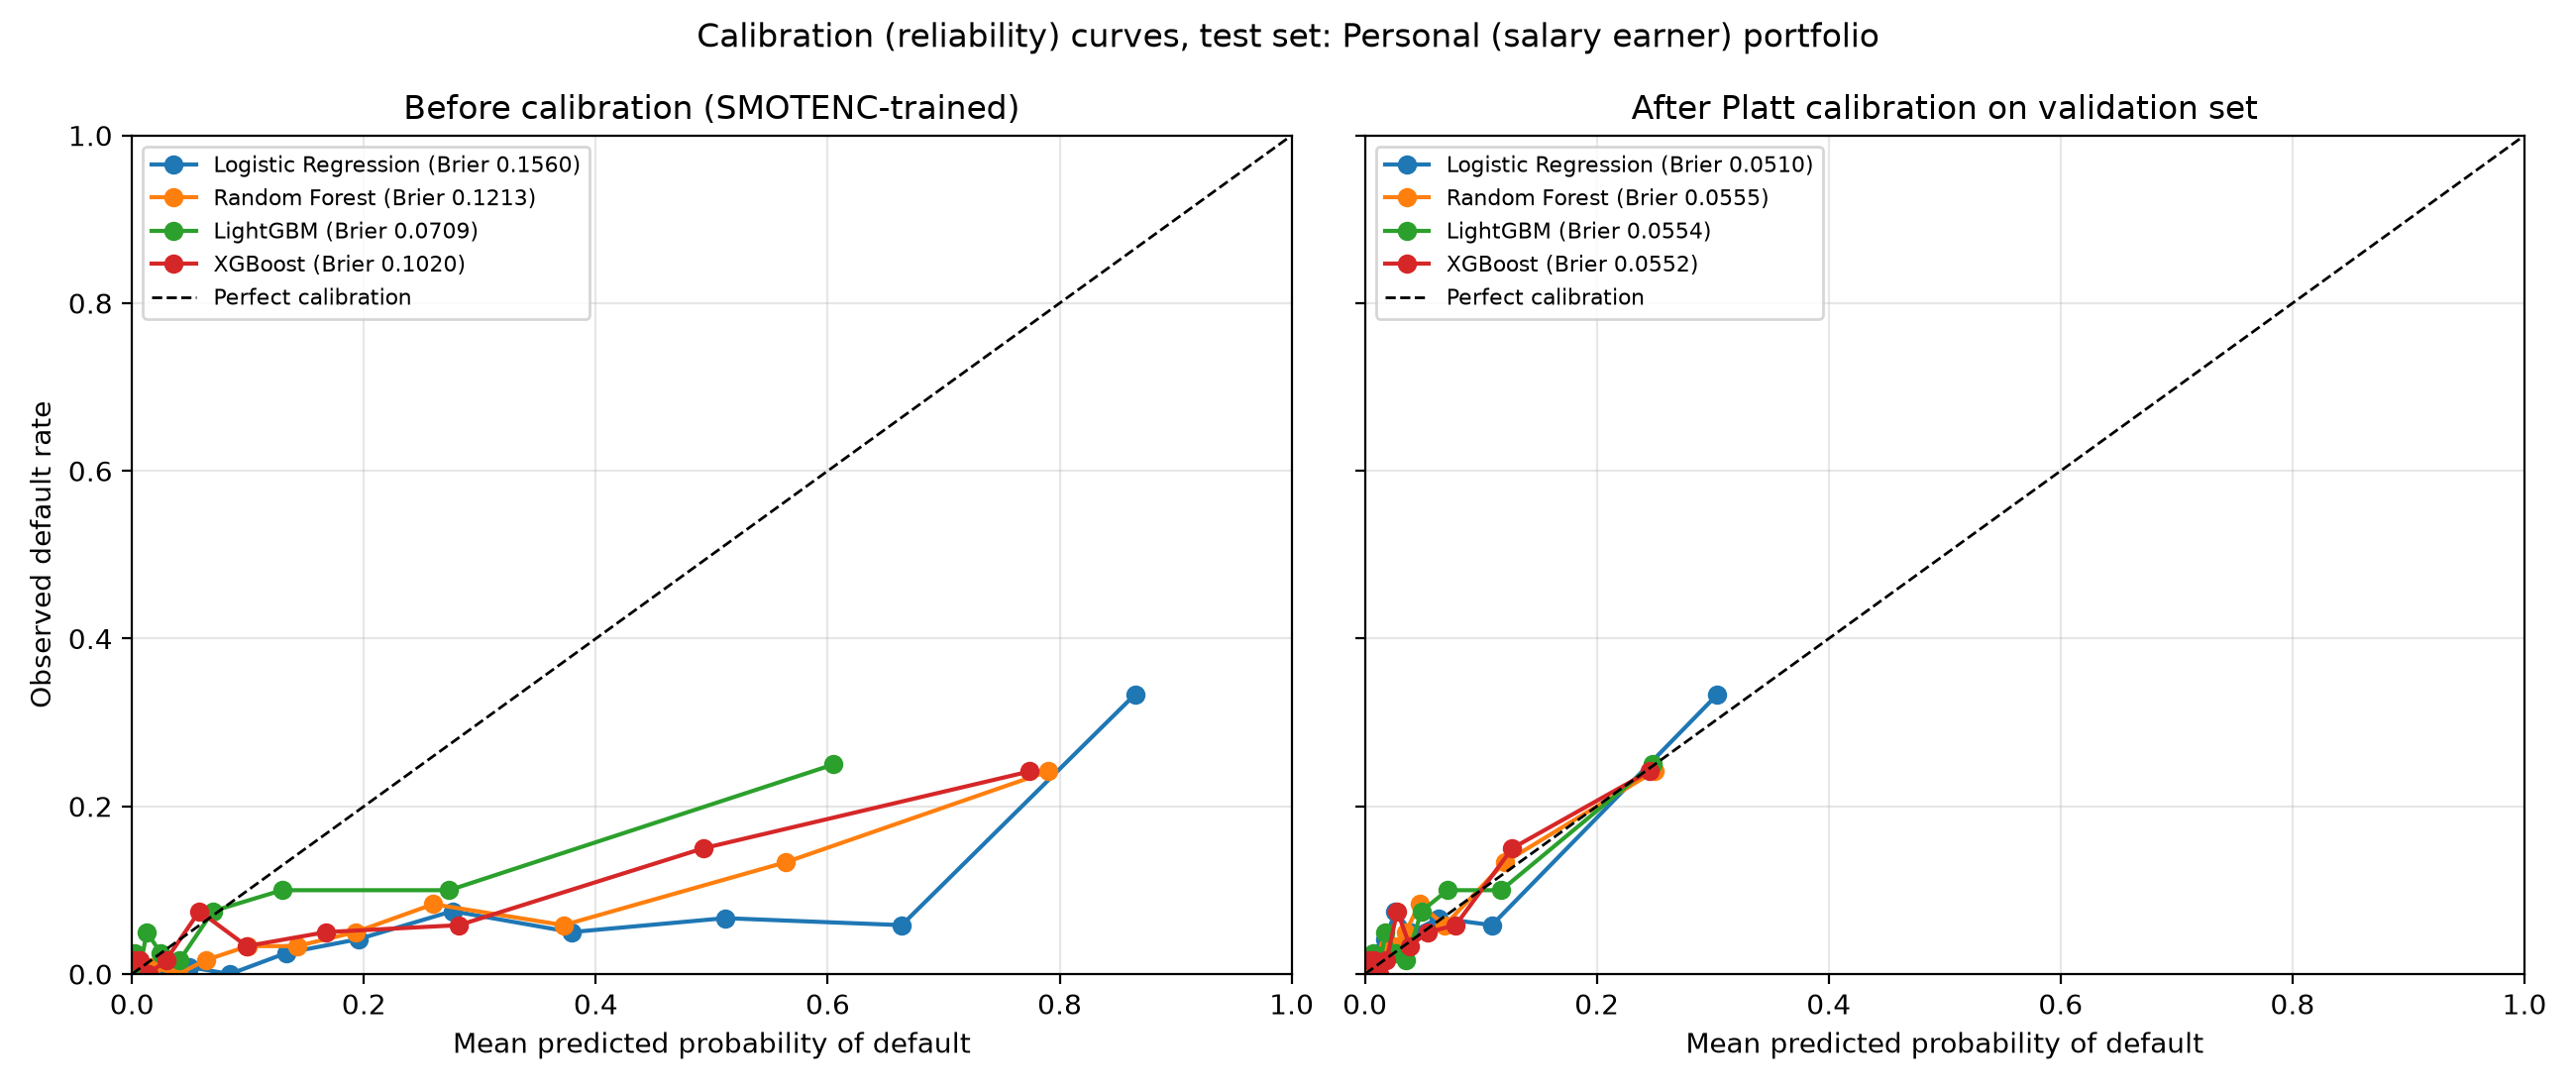

**personal_correlation.png**

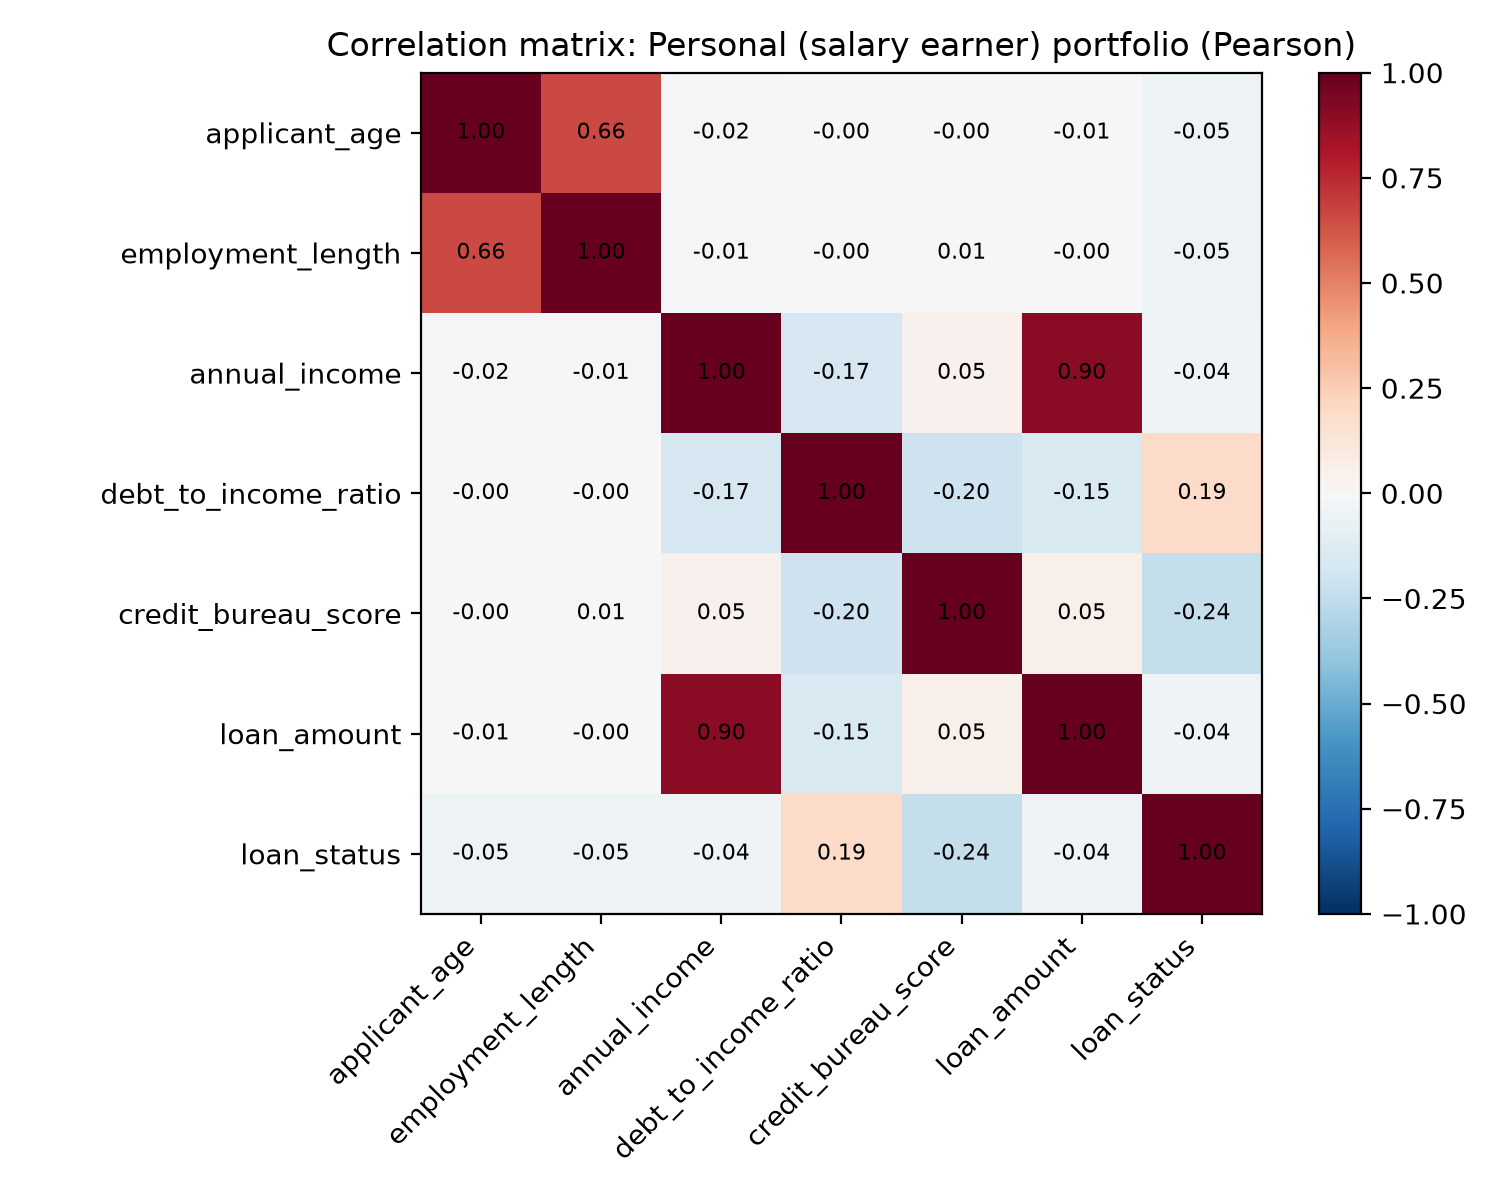

**personal_cost_curve.png**

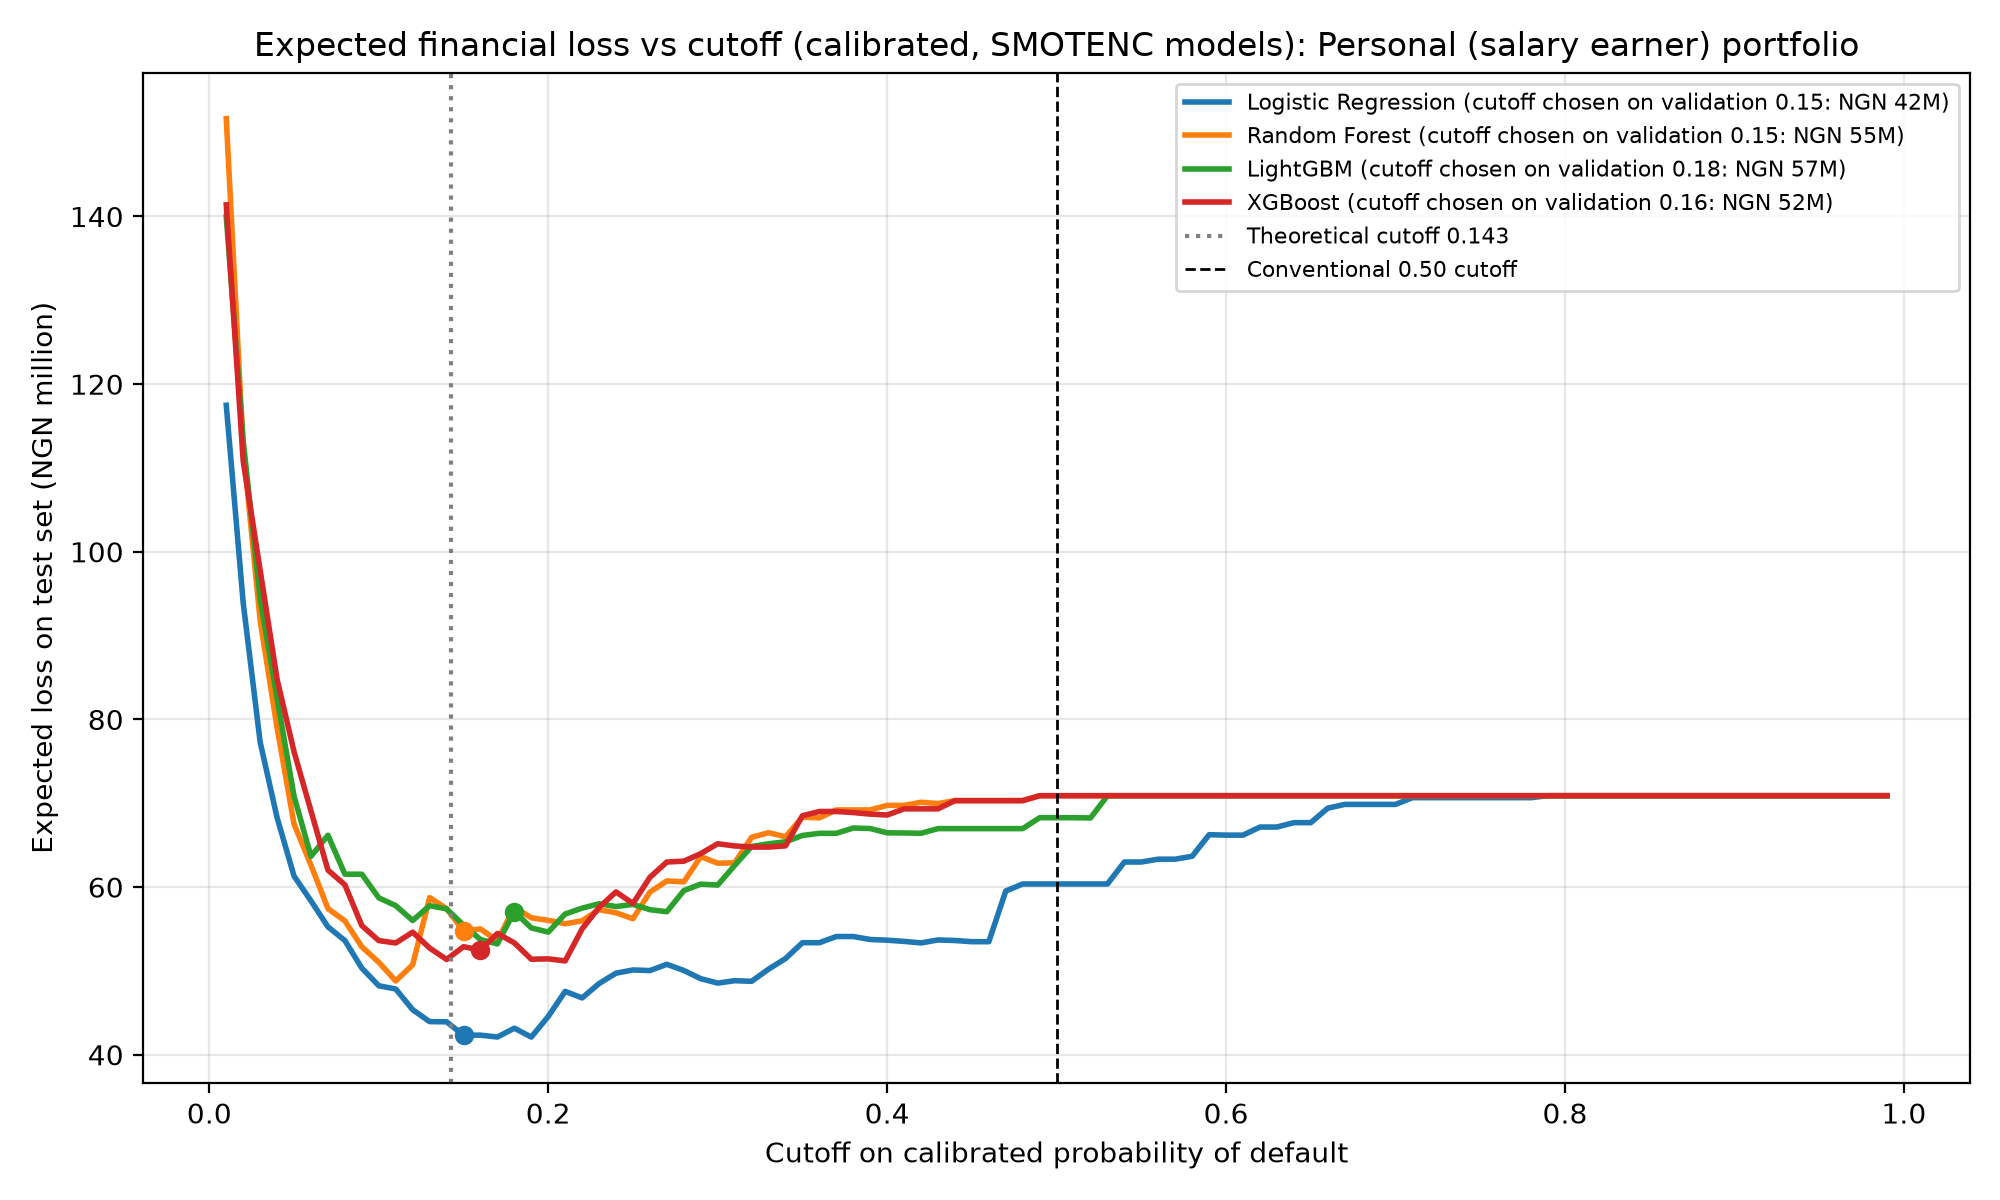

**personal_logistic_regression_shap_beeswarm.png**

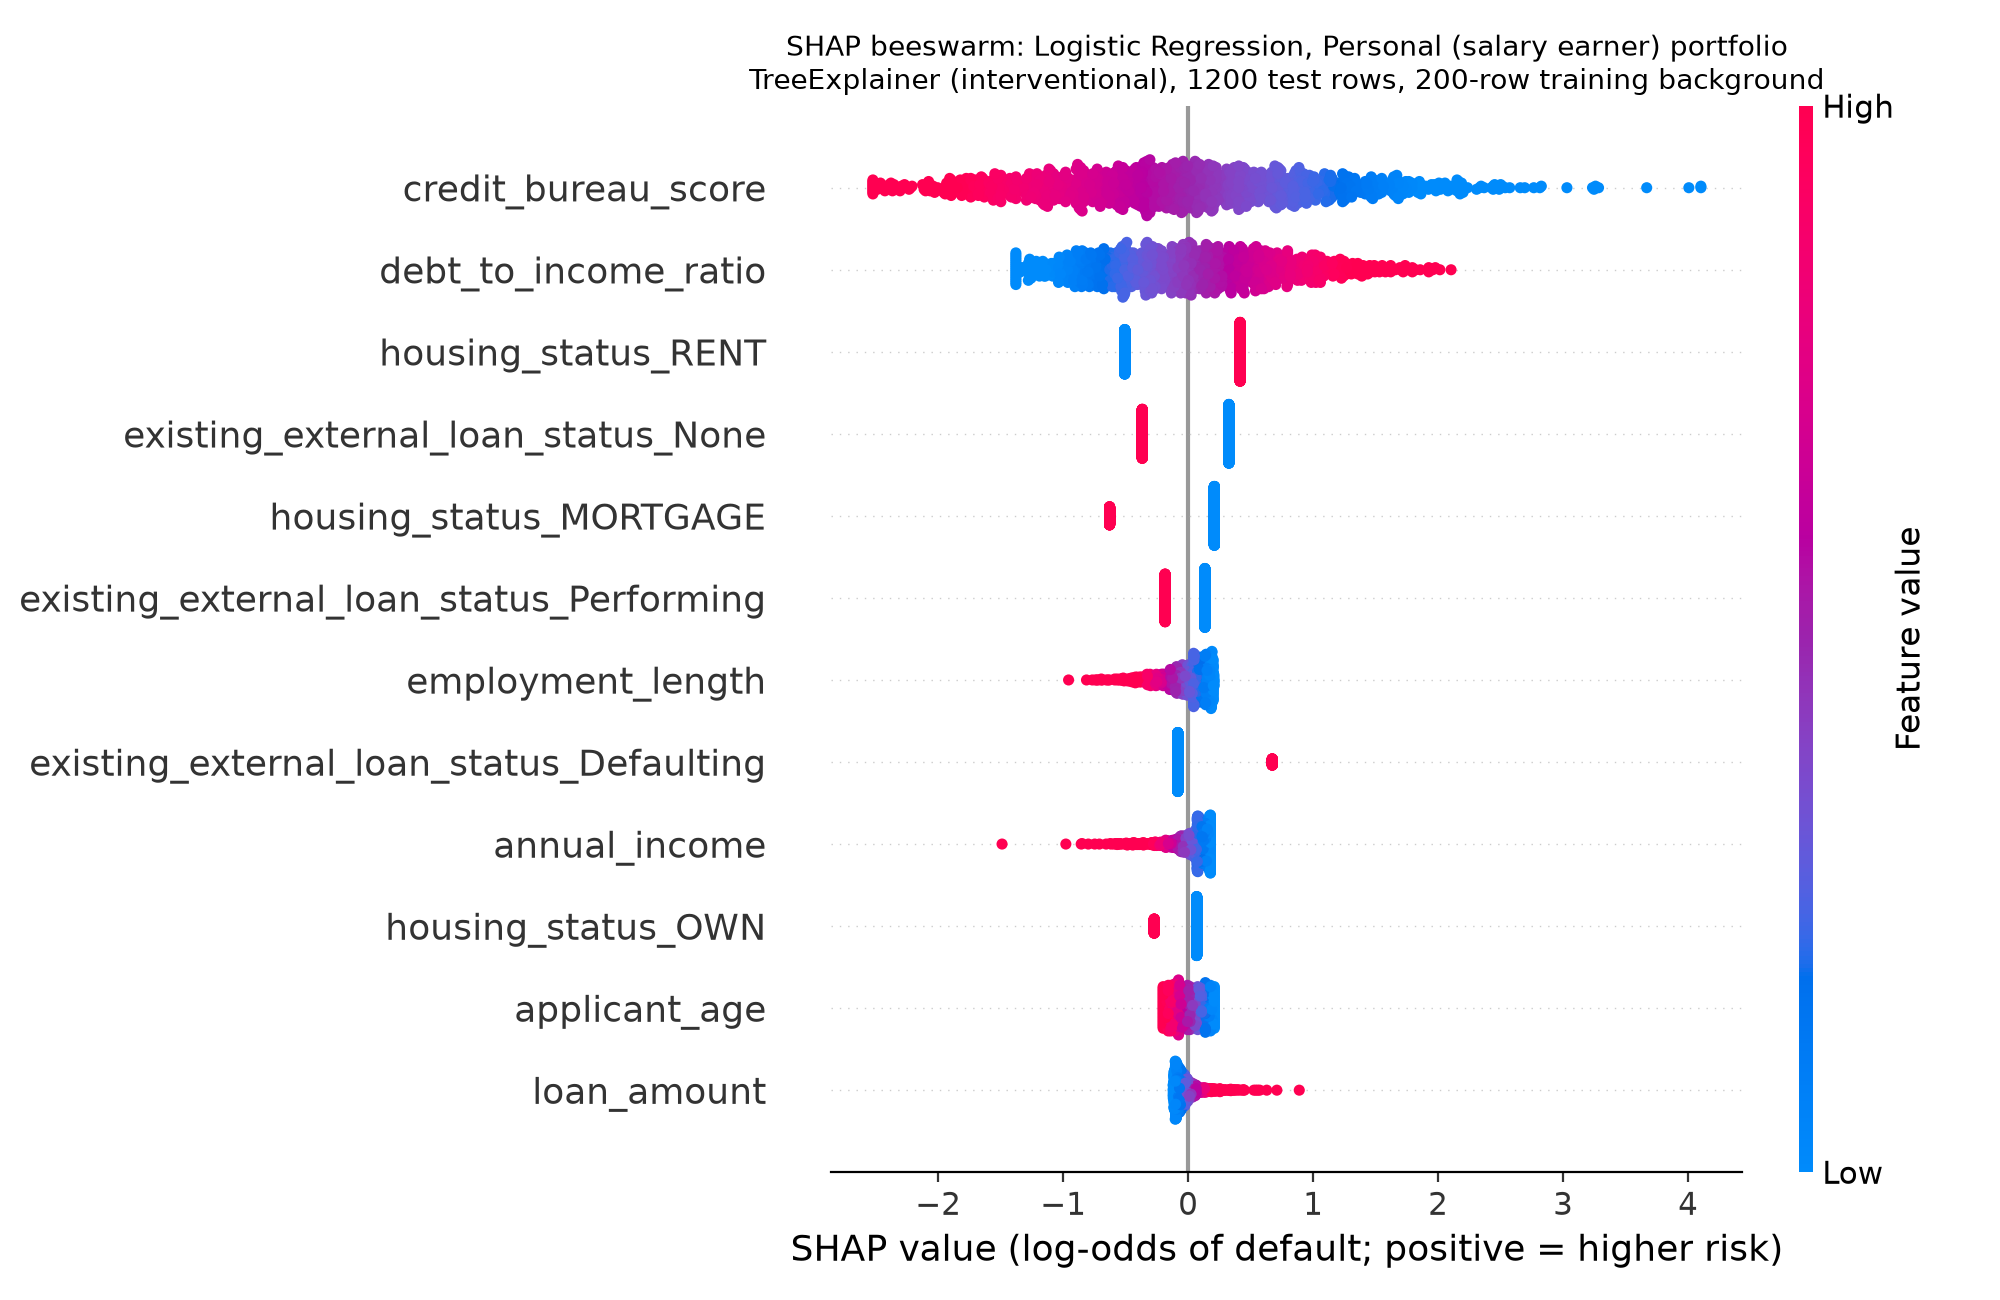

**personal_logistic_regression_shap_summary.png**

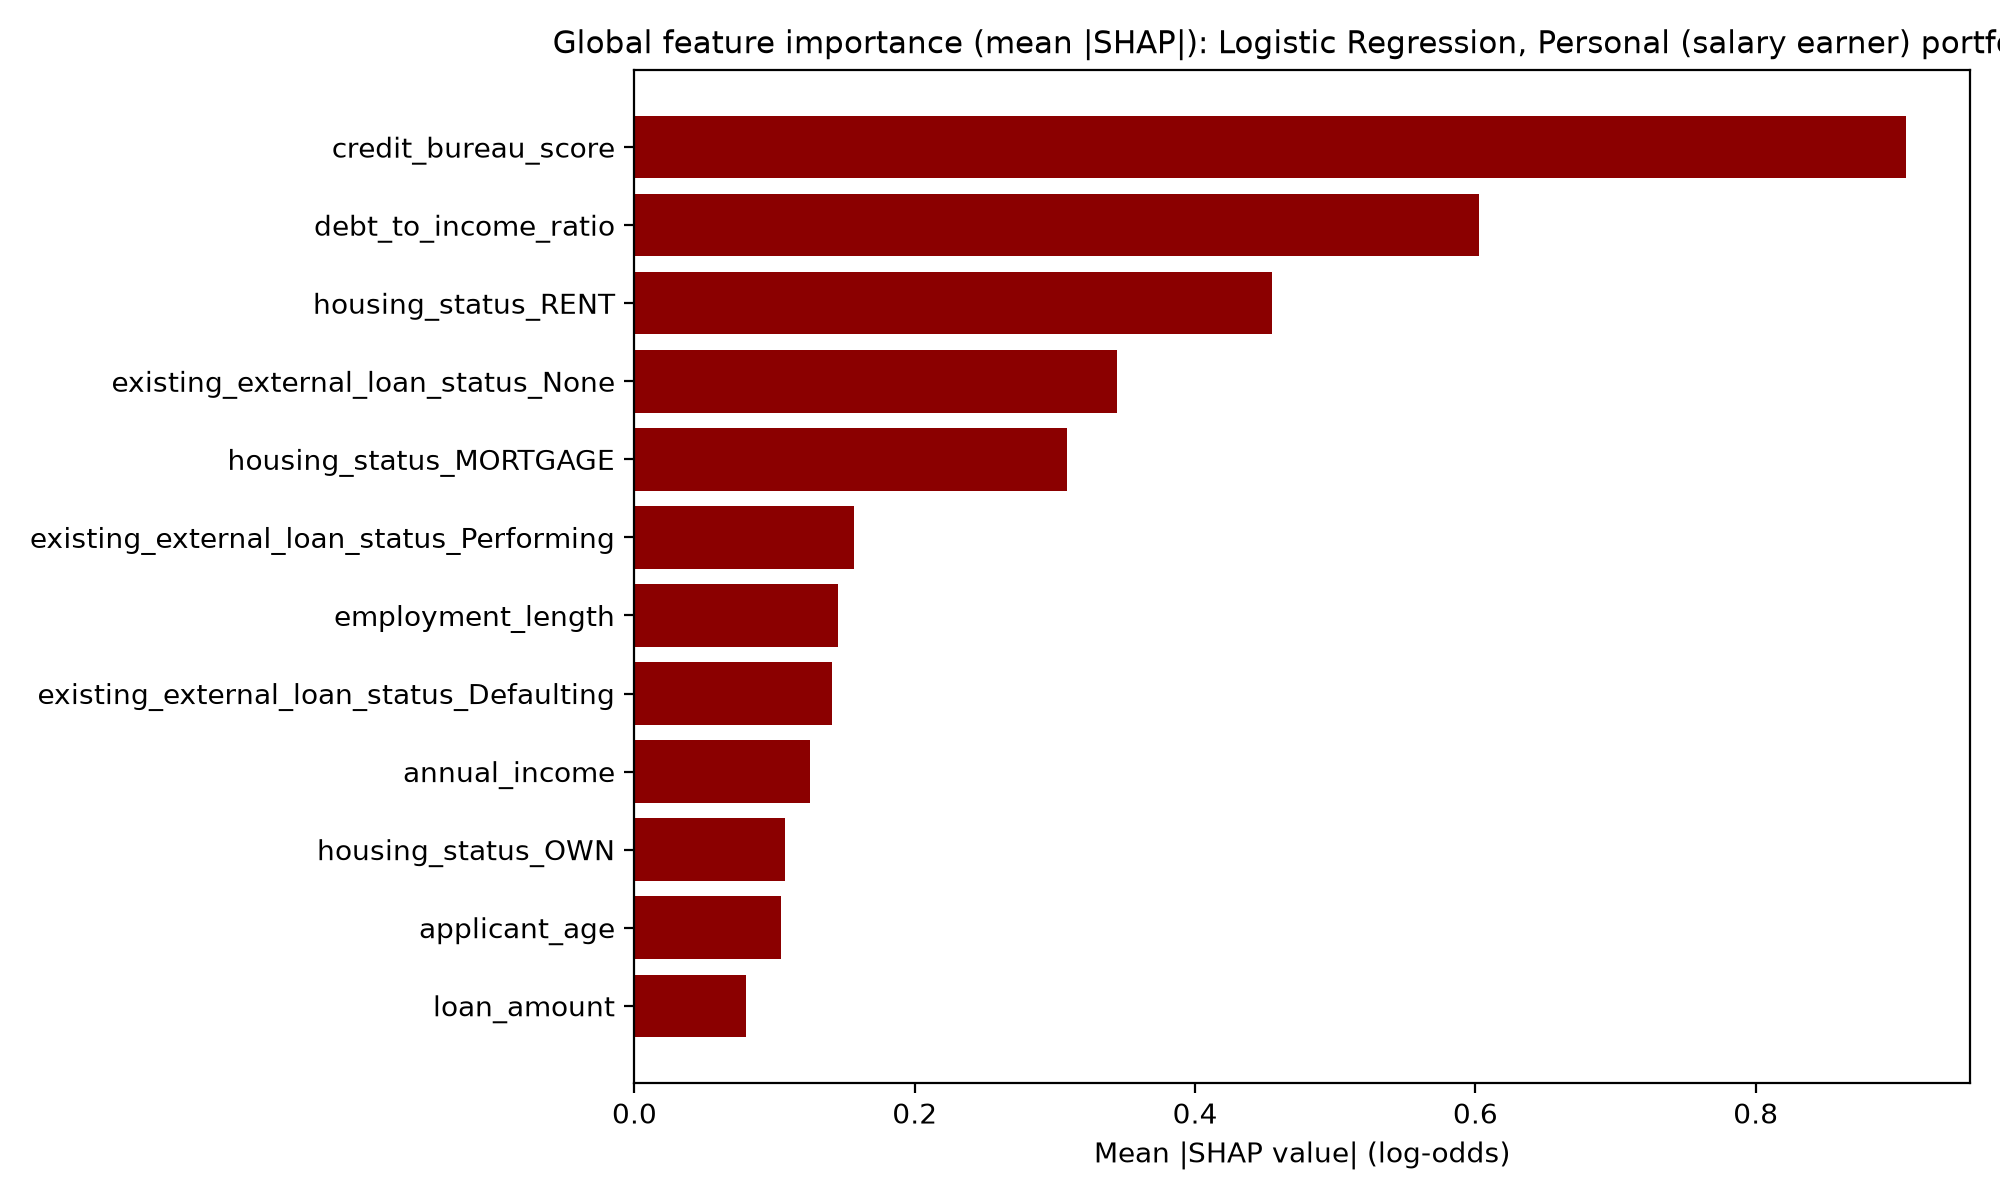

**personal_roc_pr_curves.png**

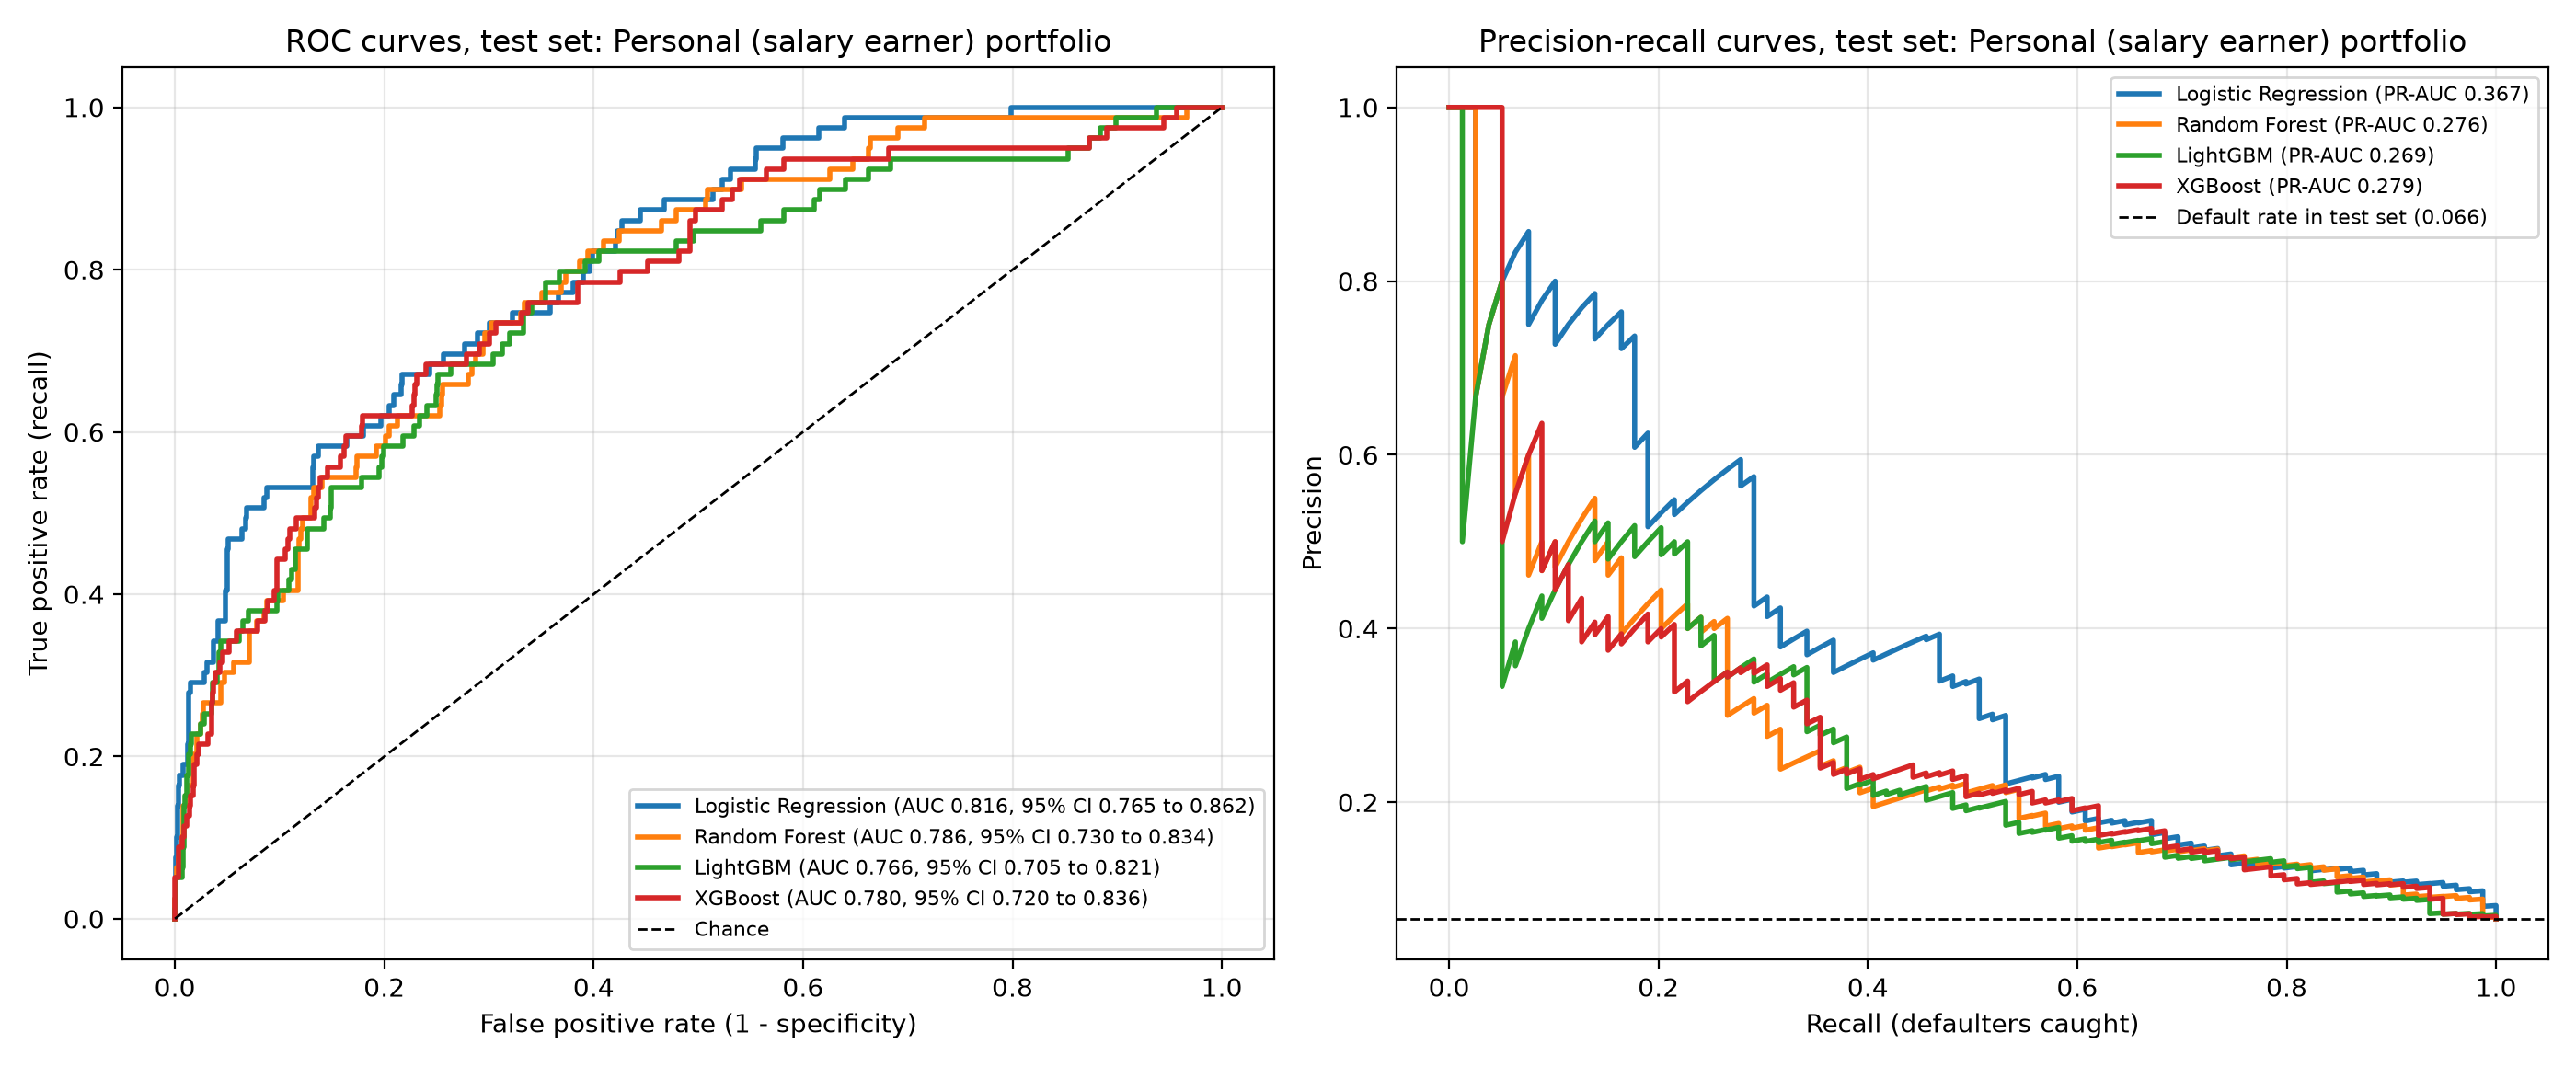

**personal_xgboost_shap_beeswarm.png**

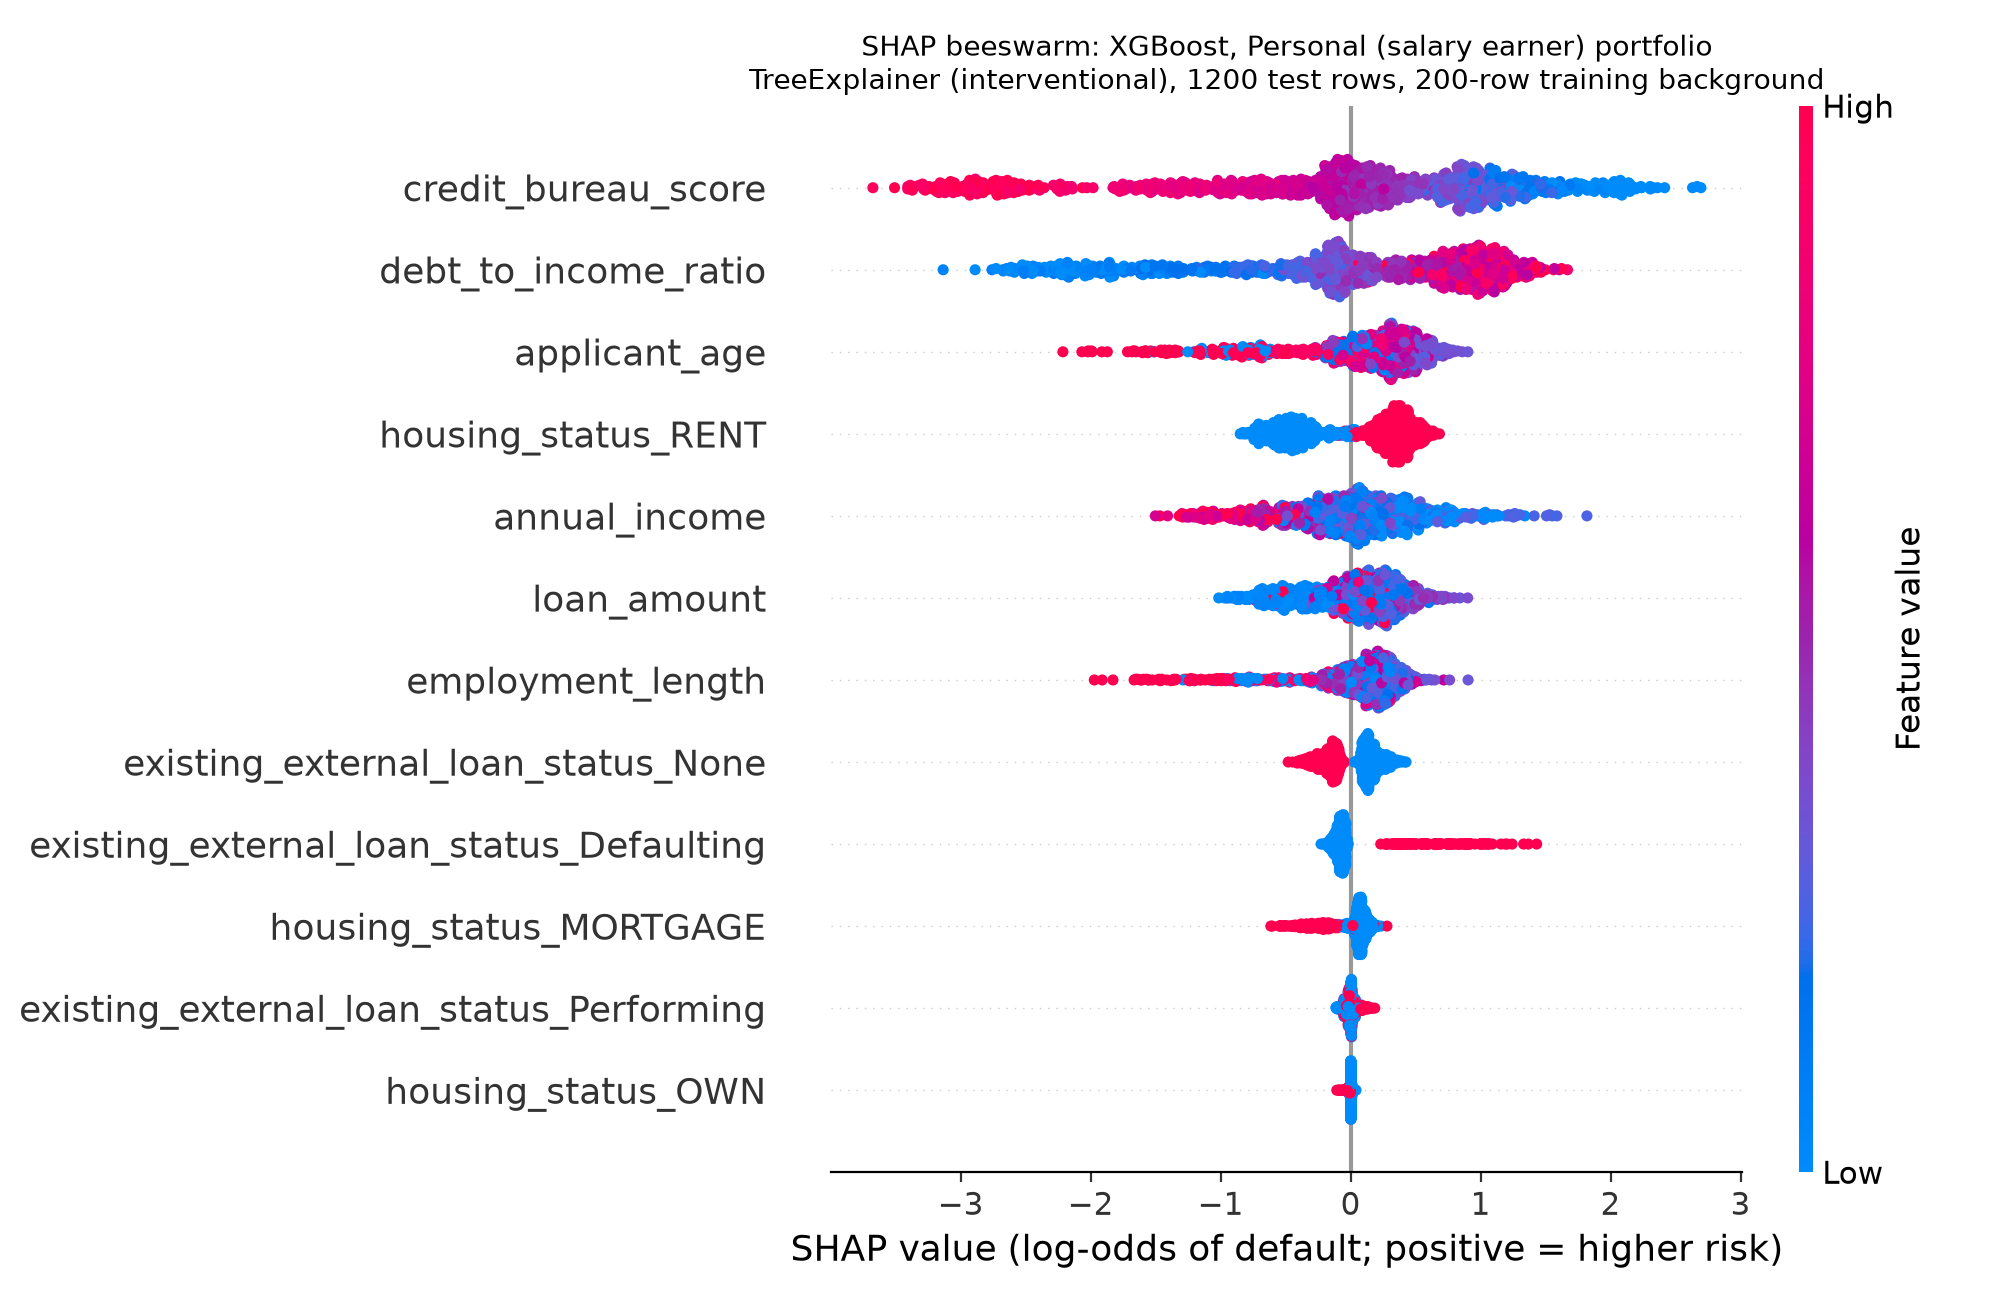

**personal_xgboost_shap_summary.png**

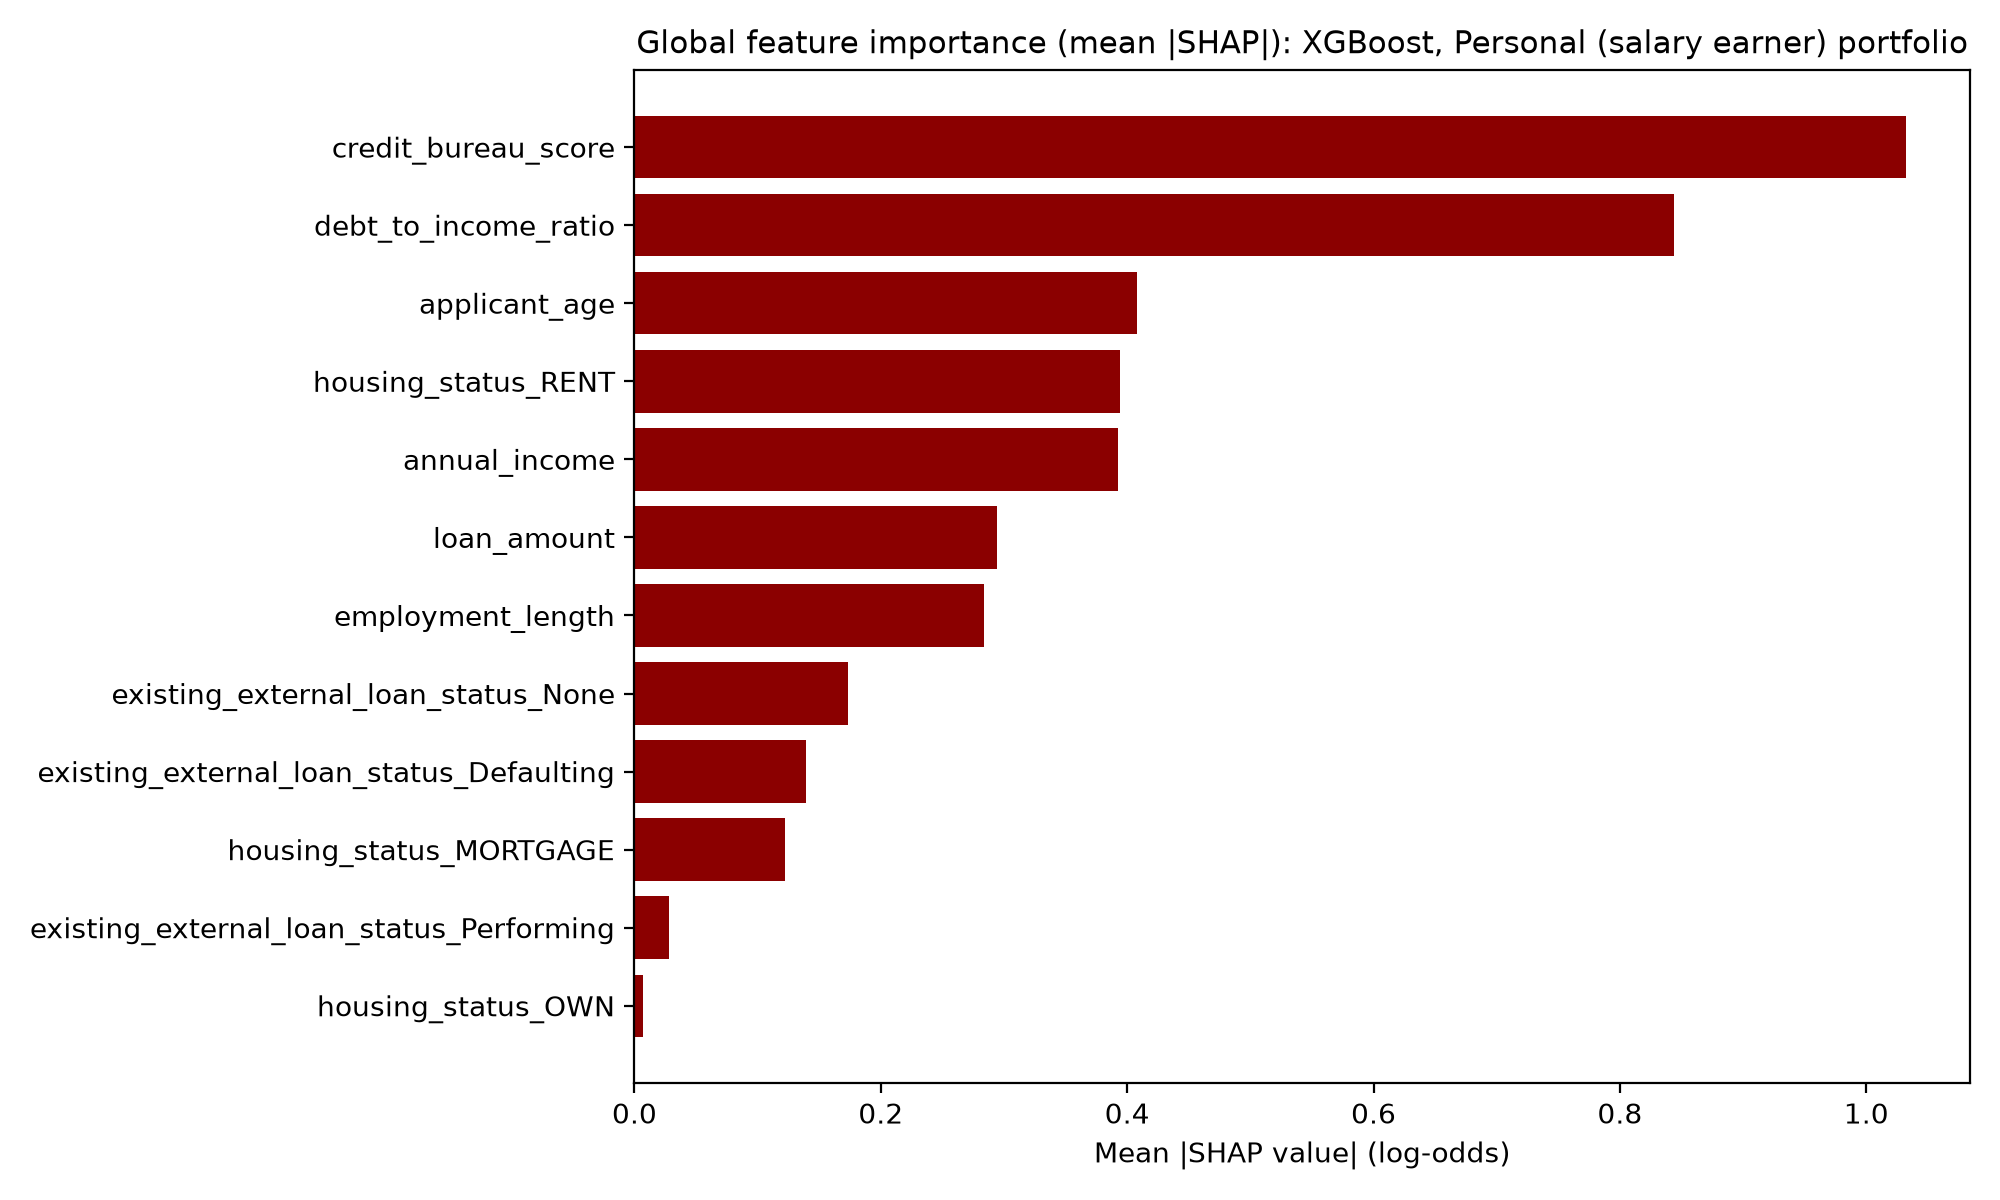

**personal_xgboost_shap_waterfall.png**

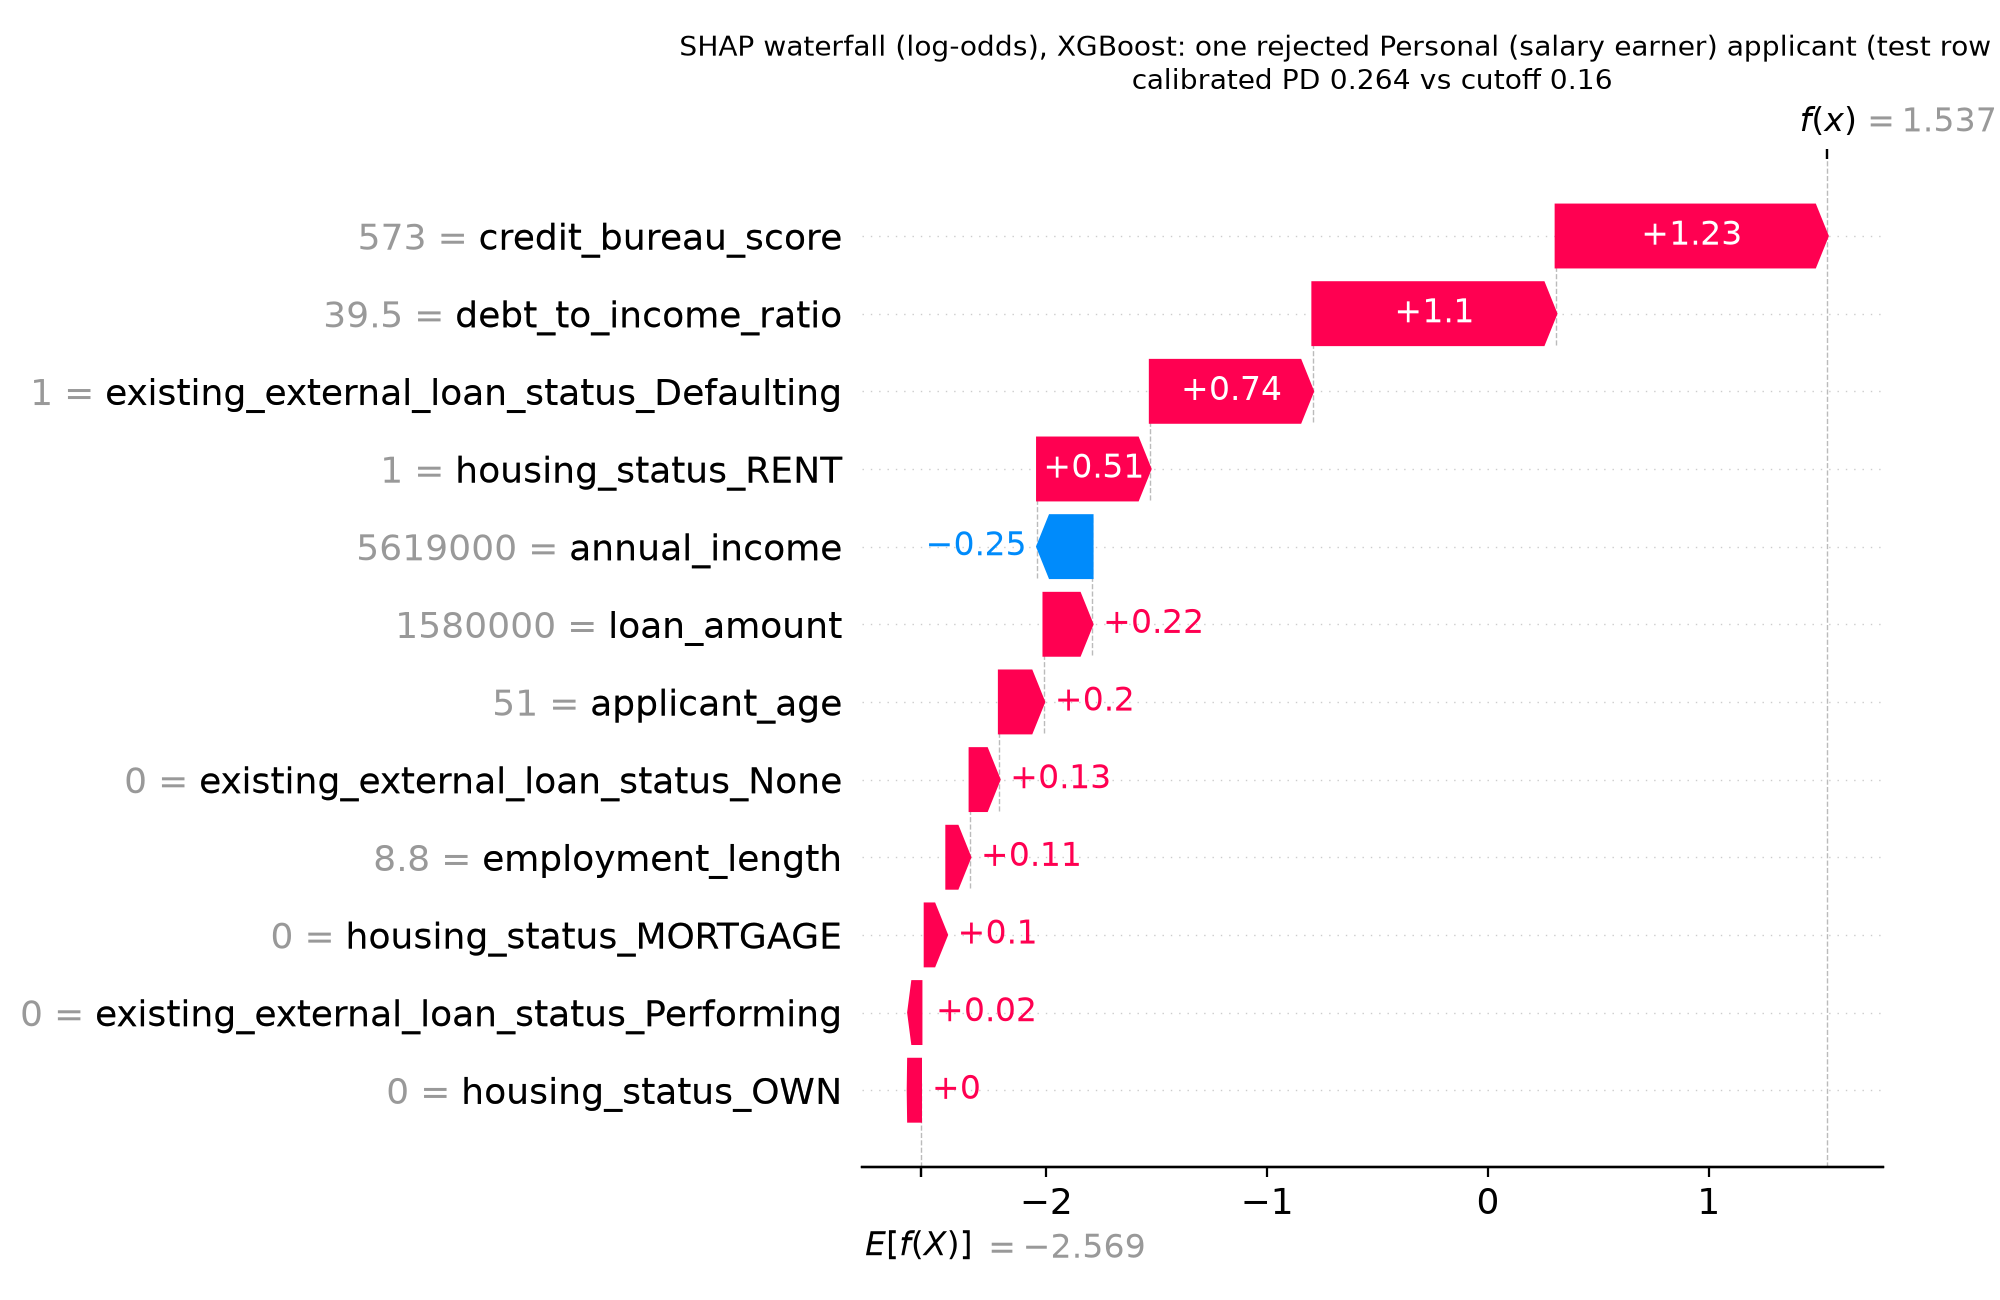

**retail_calibration.png**

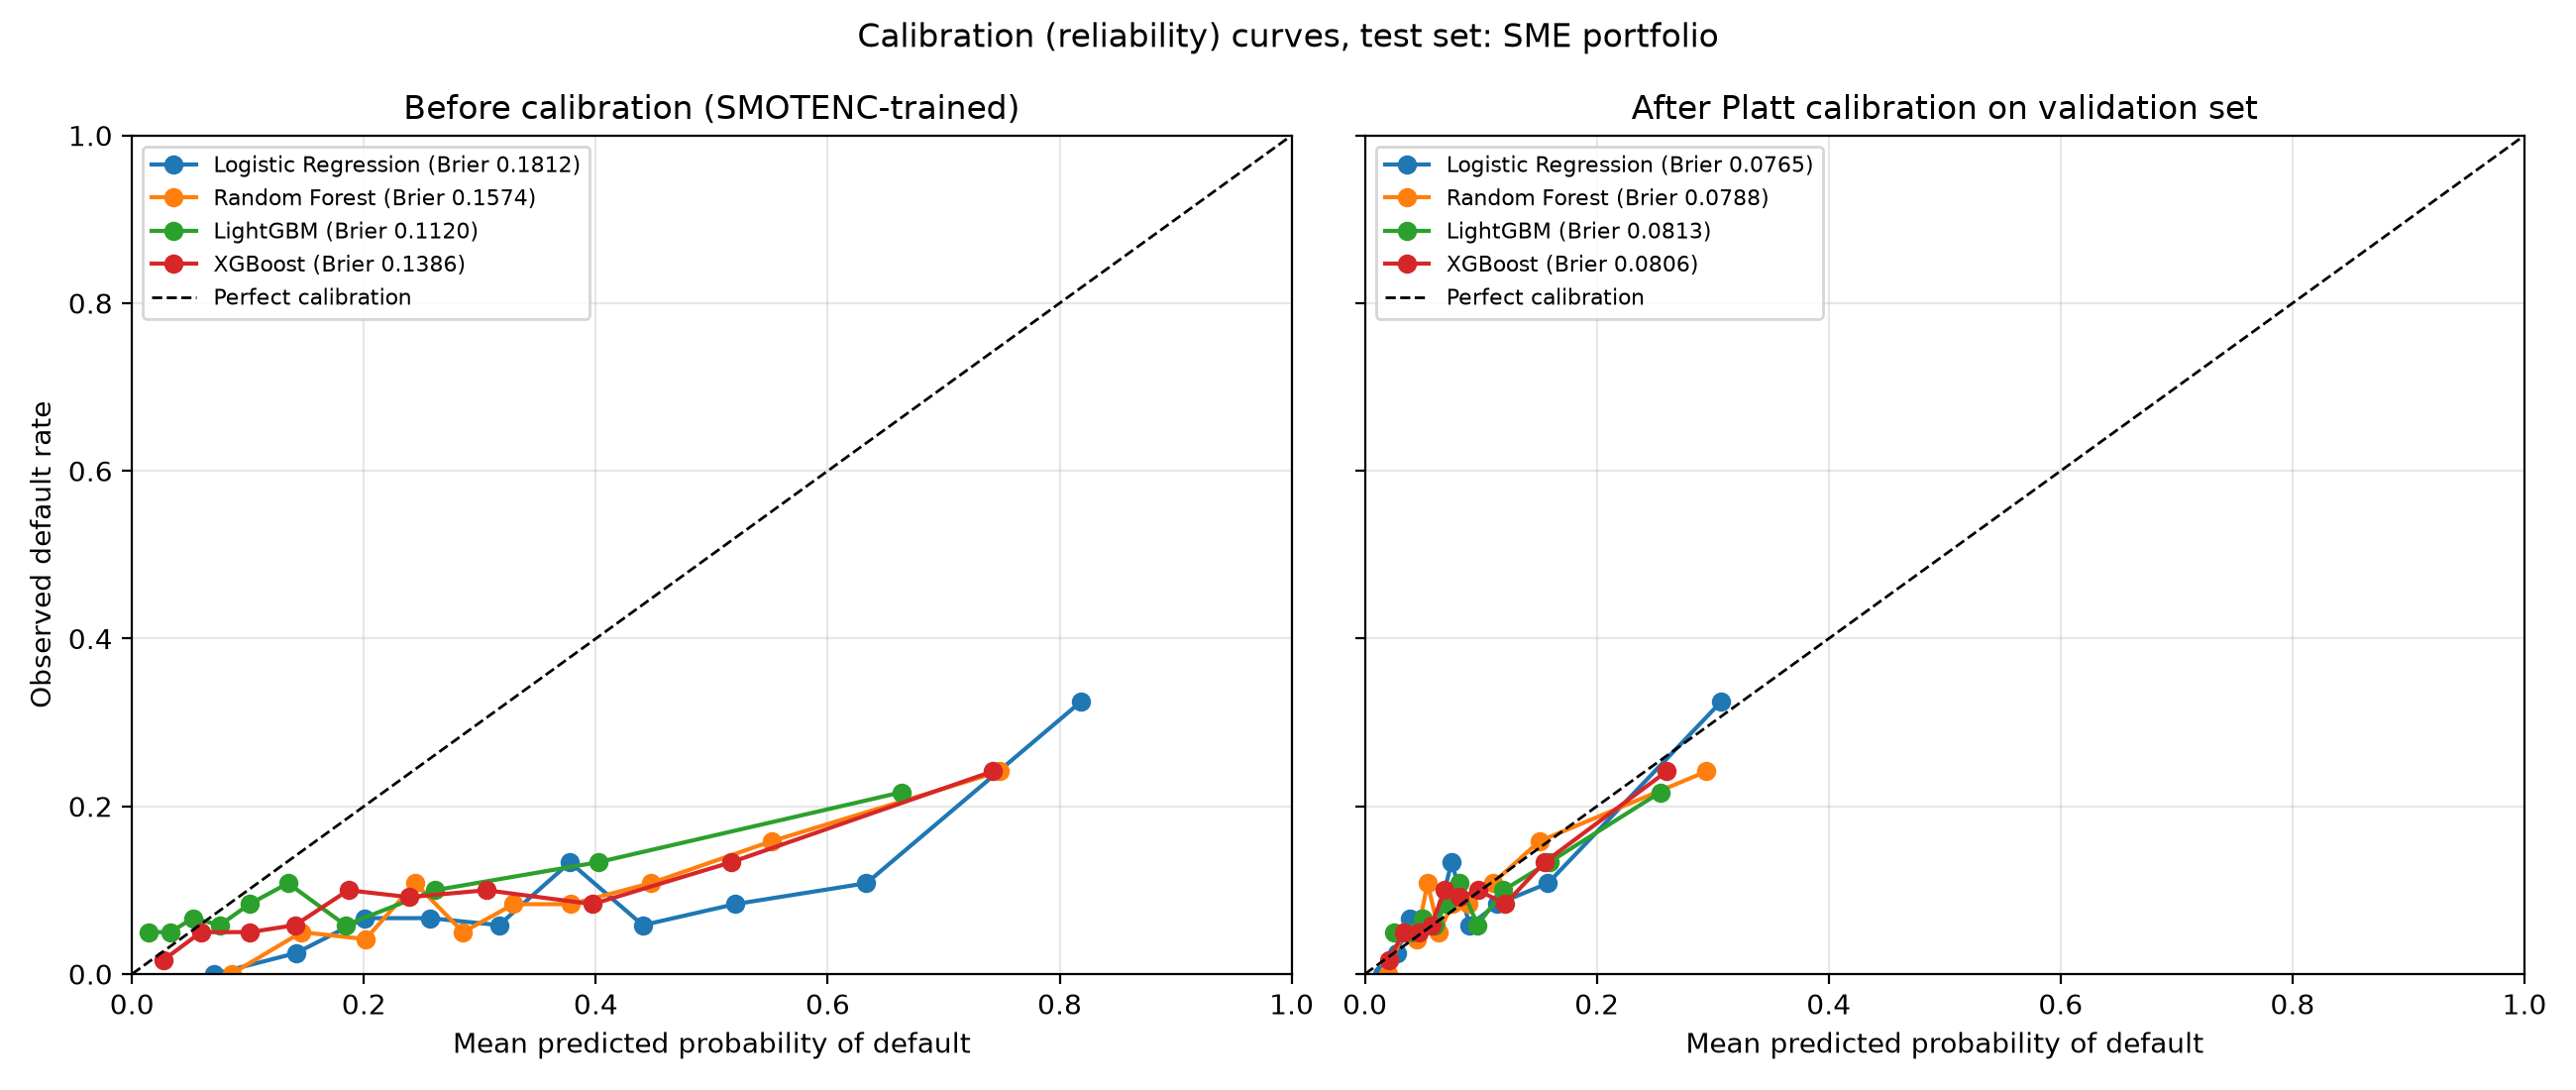

**retail_correlation.png**

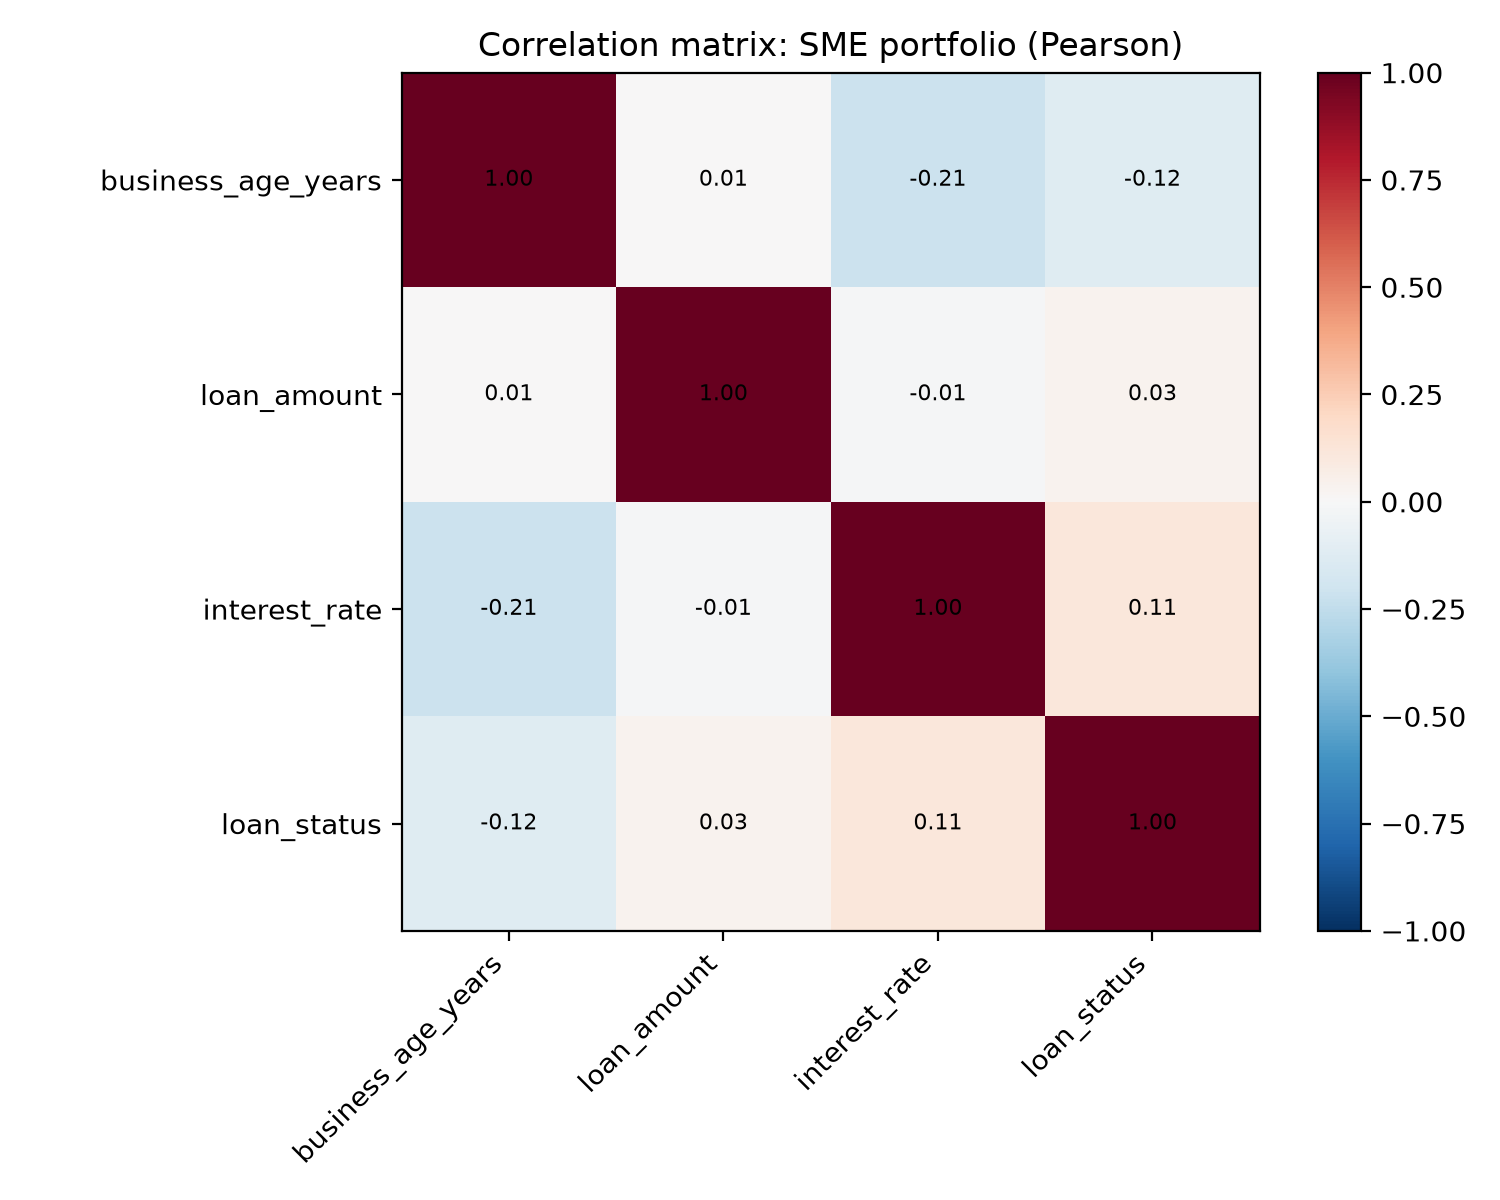

**retail_cost_curve.png**

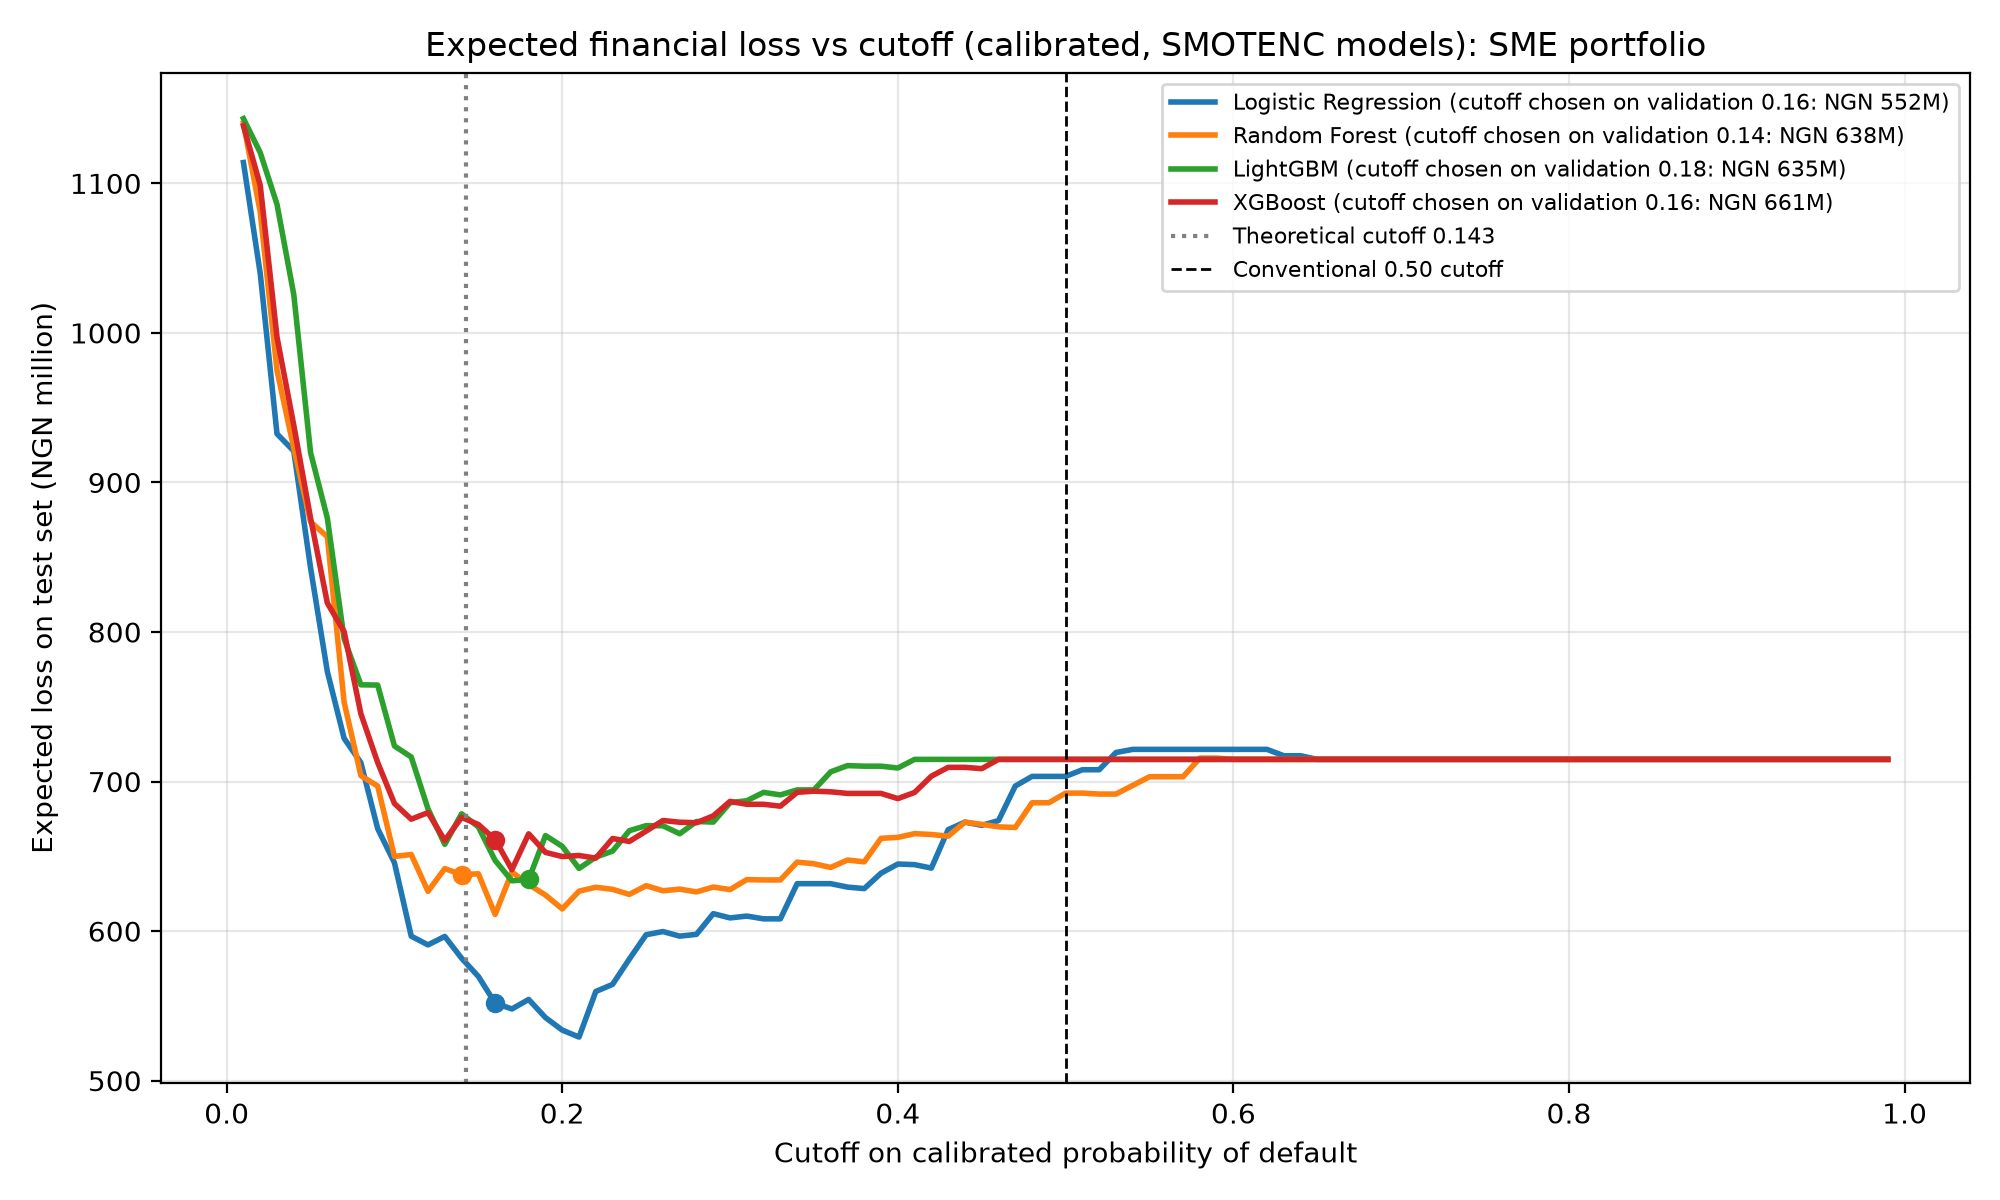

**retail_logistic_regression_shap_beeswarm.png**

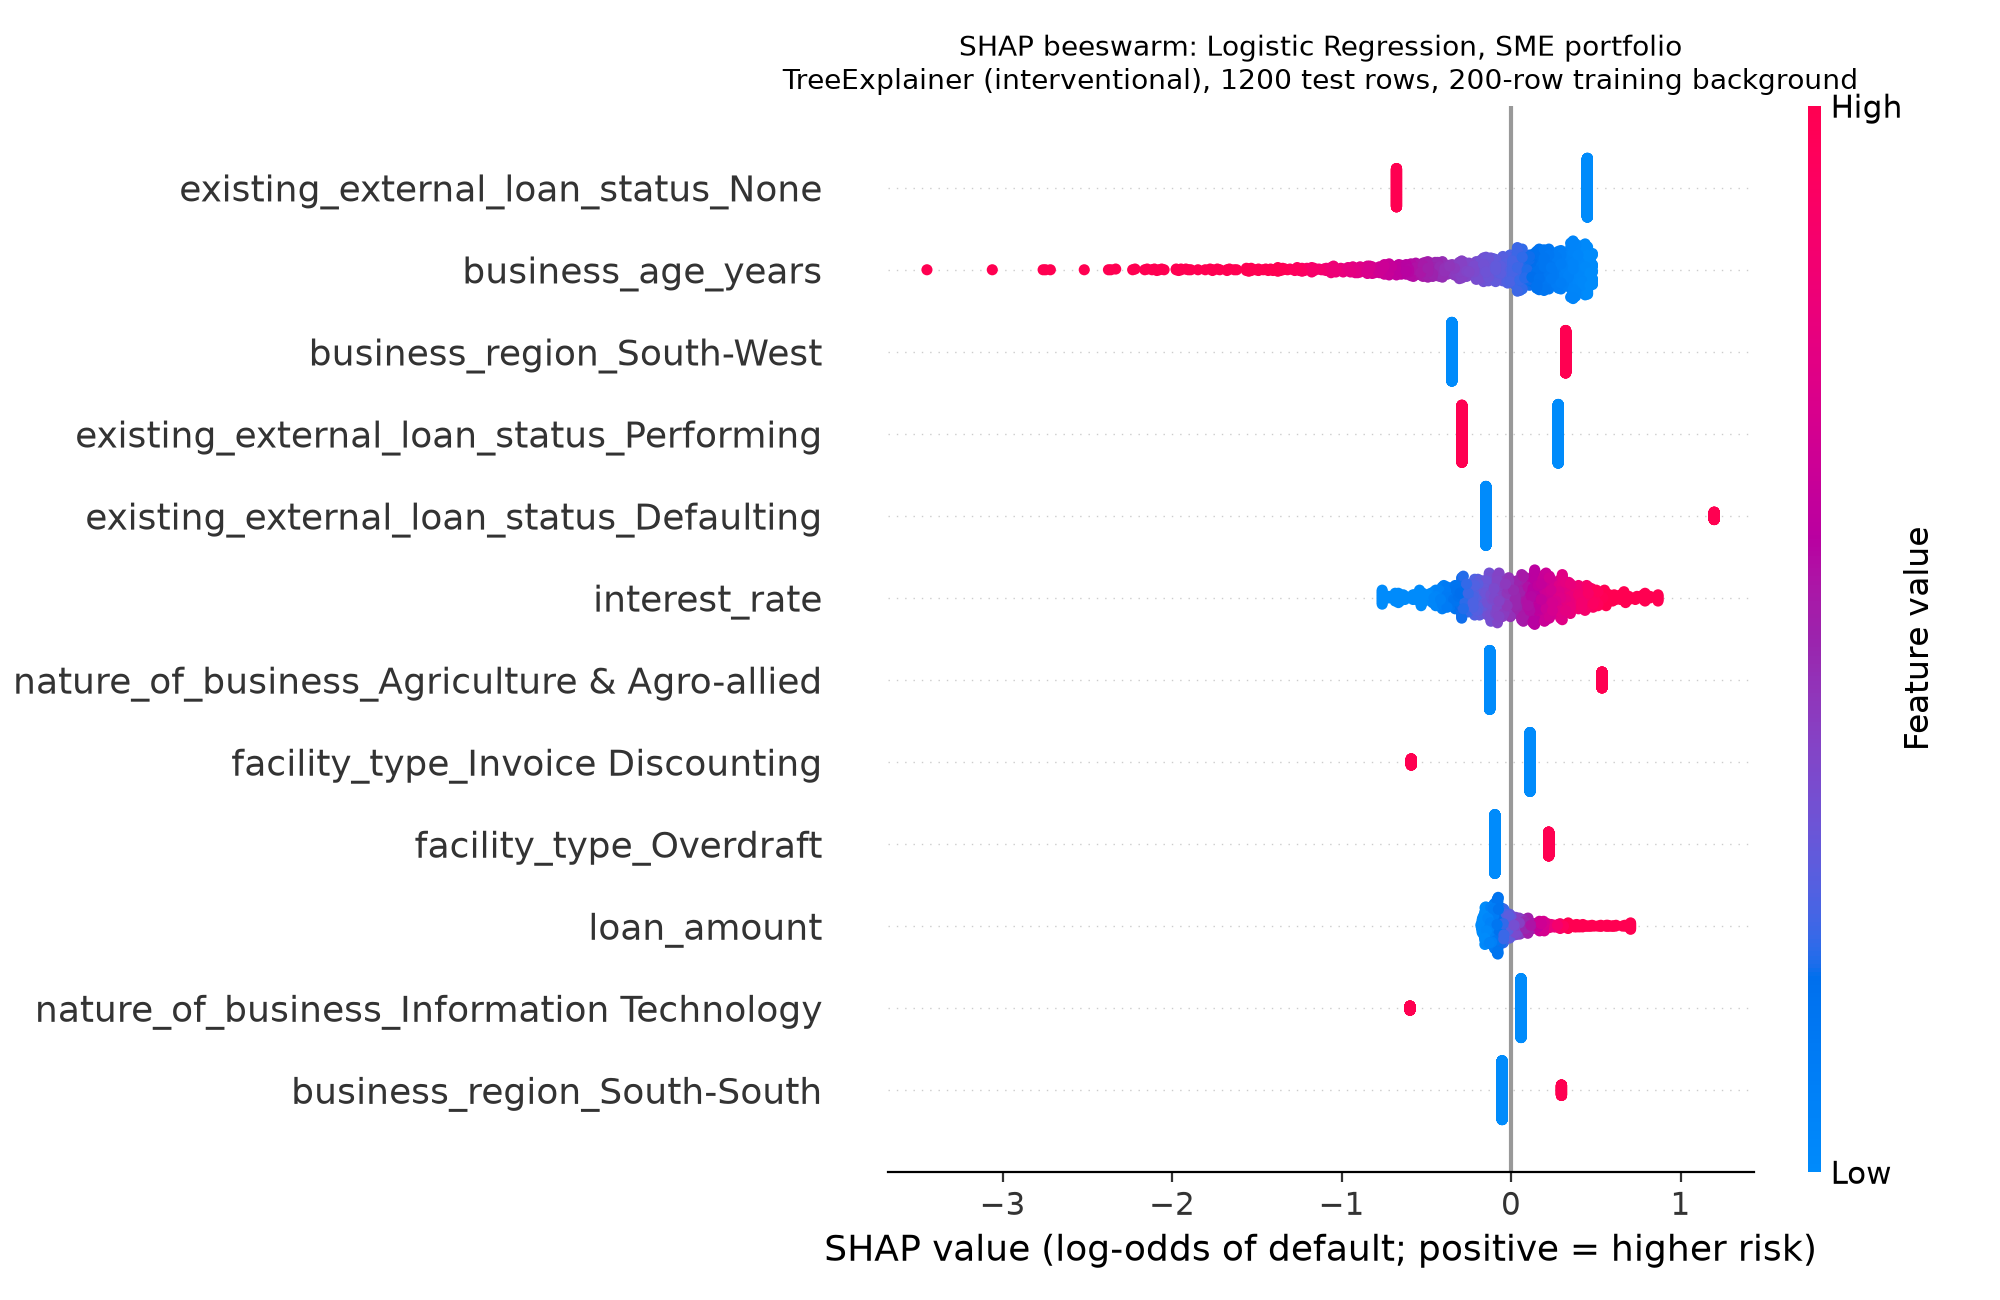

**retail_logistic_regression_shap_summary.png**

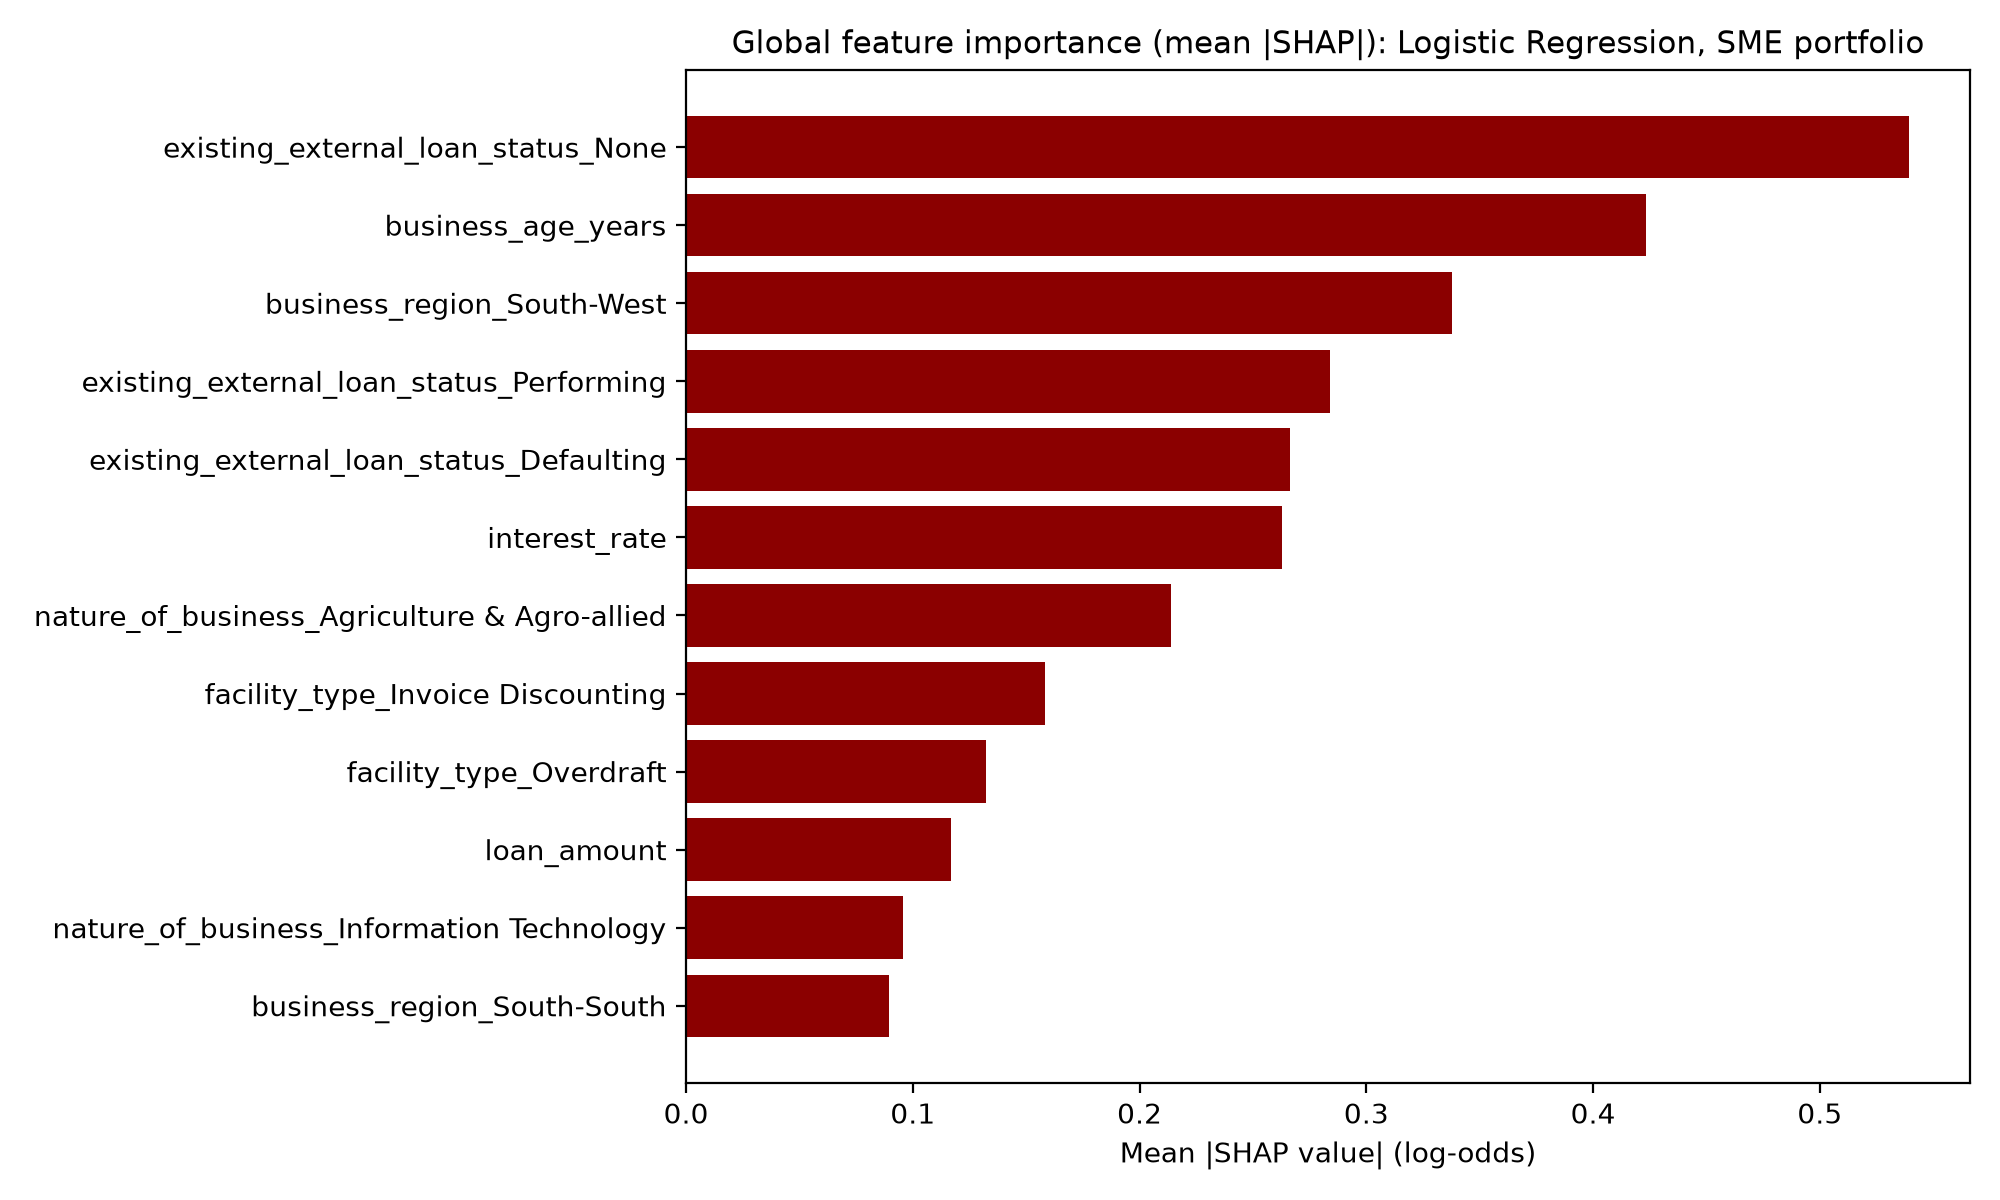

**retail_roc_pr_curves.png**

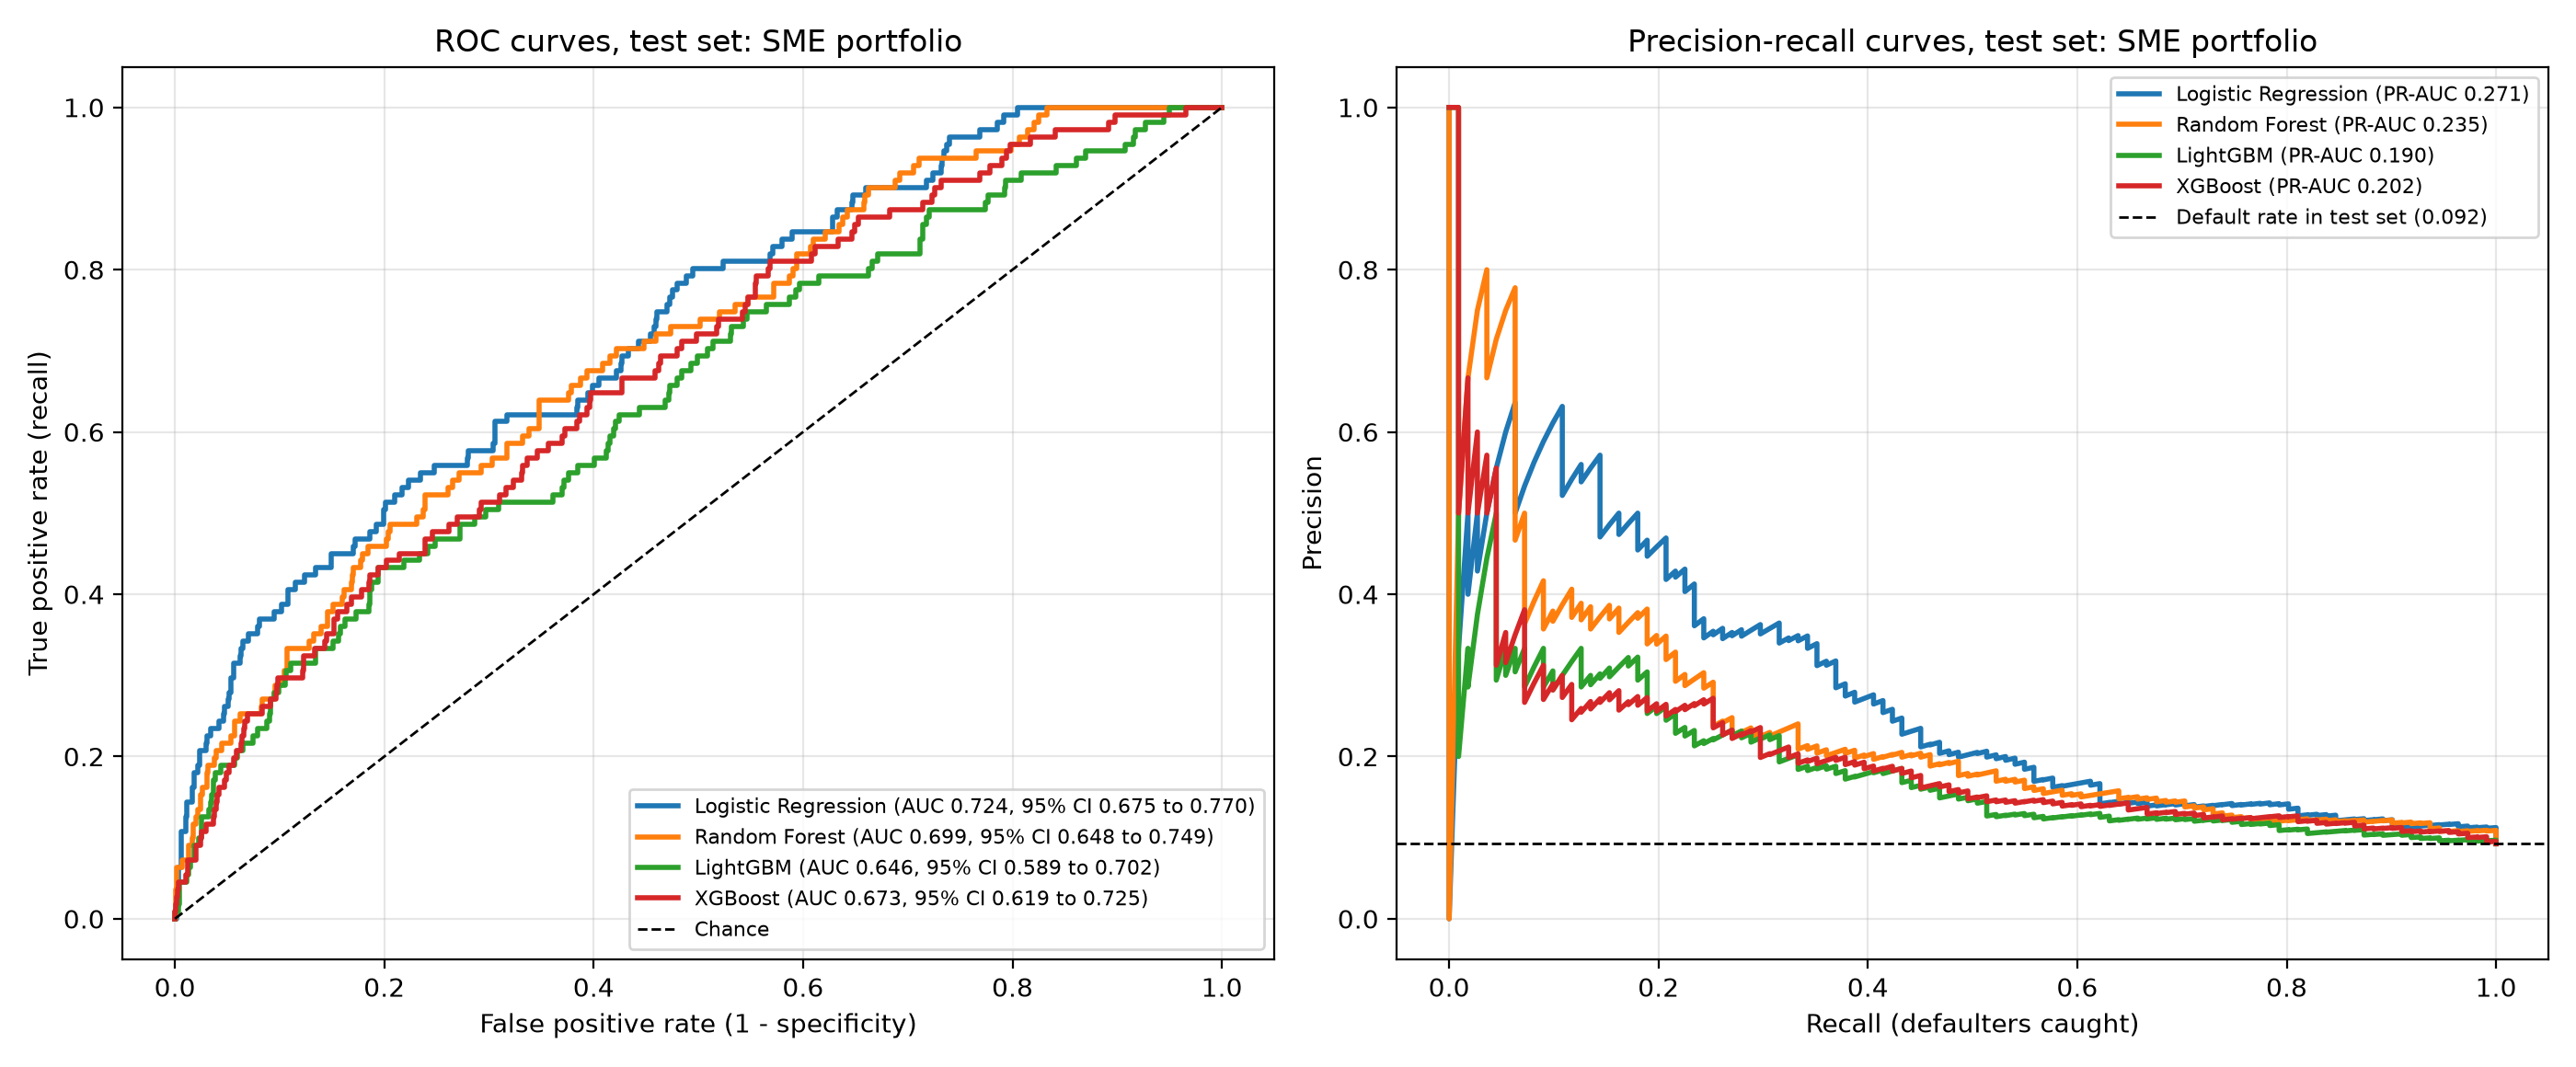

**retail_xgboost_shap_beeswarm.png**

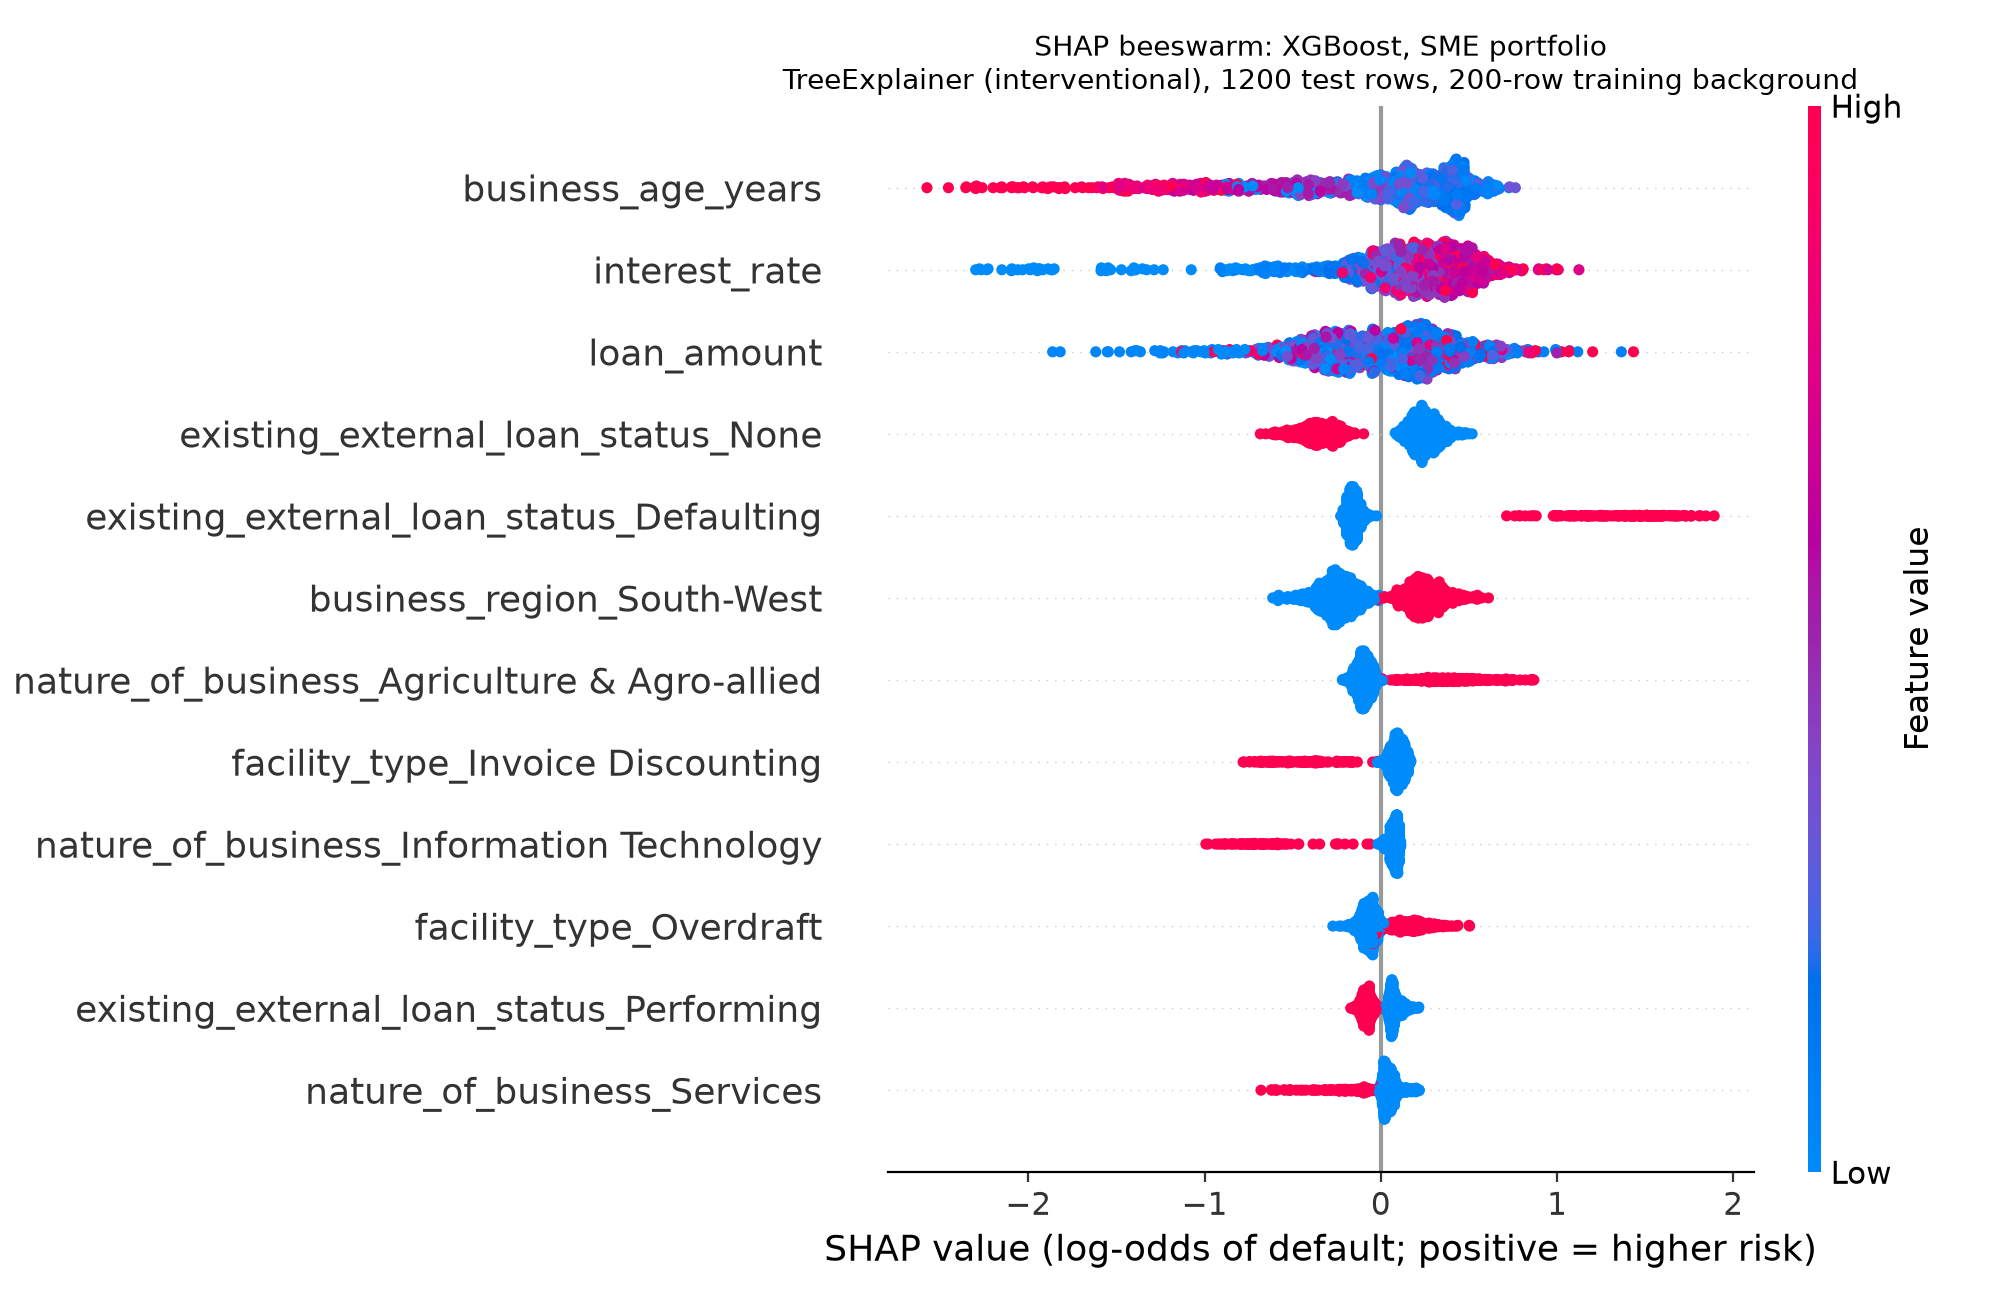

**retail_xgboost_shap_summary.png**

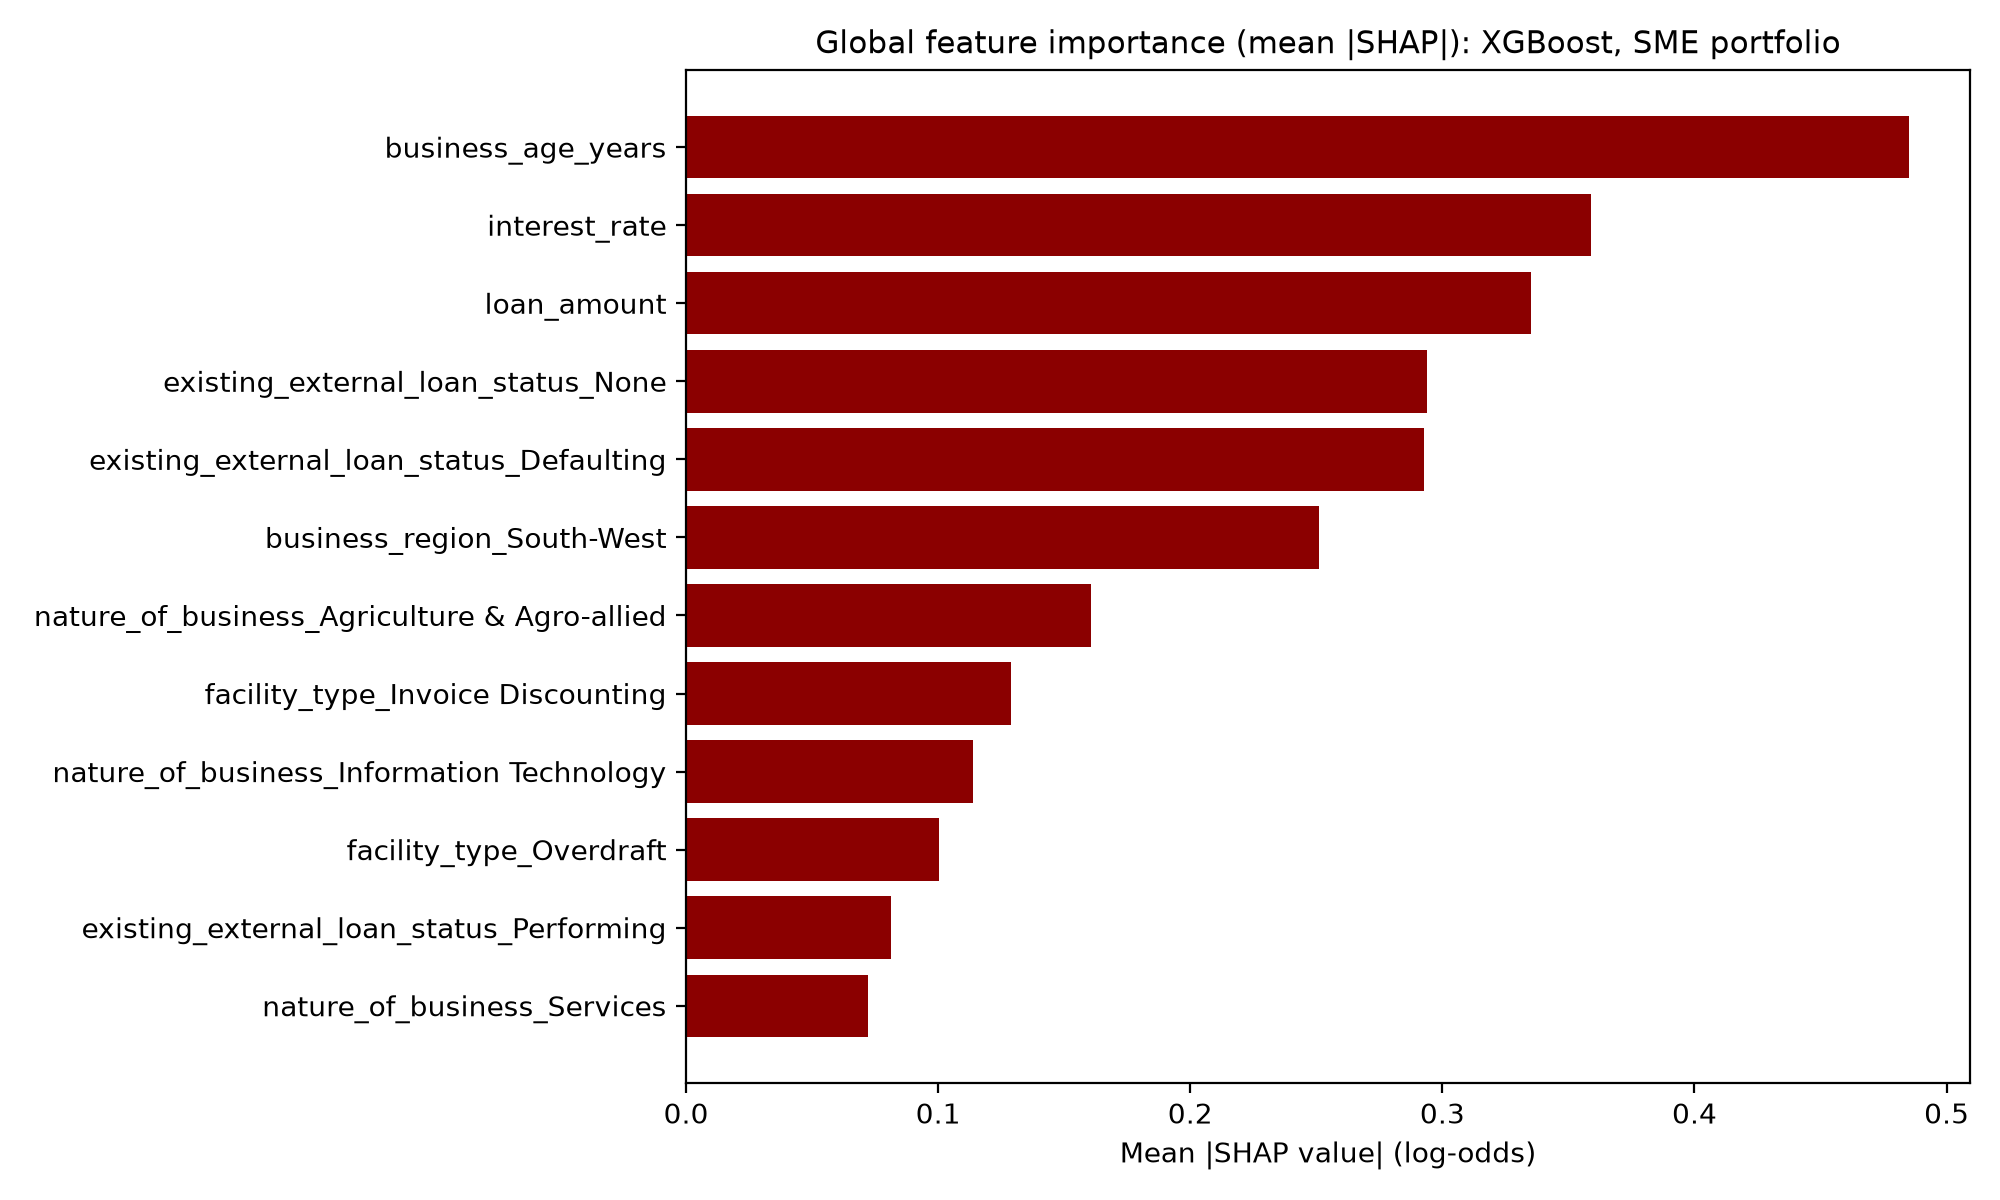

**retail_xgboost_shap_waterfall.png**

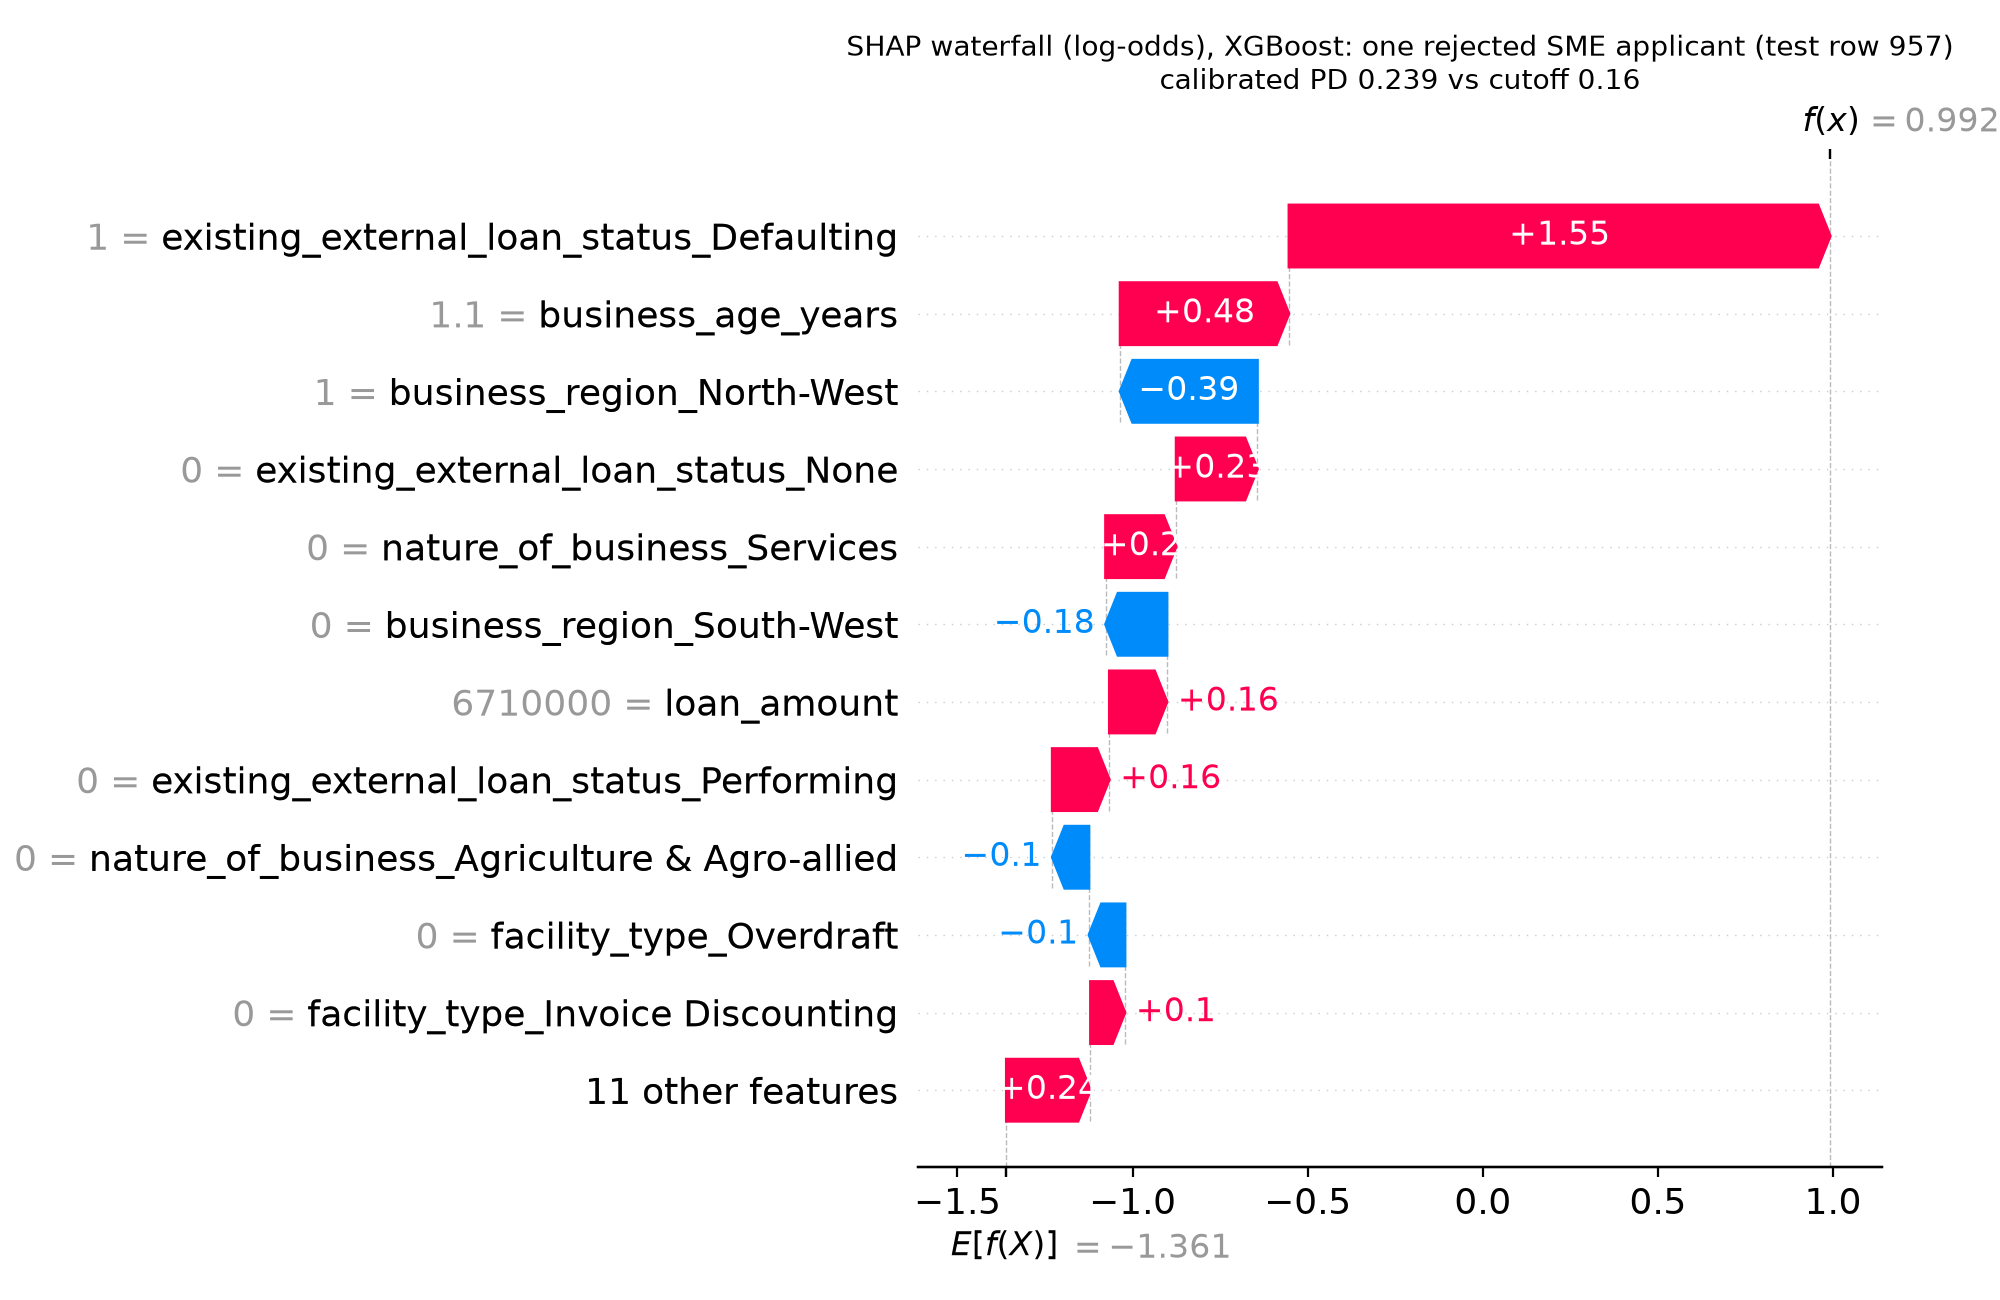

In [5]:
F = 'results/thesis/figures'
for f in sorted(os.listdir(F)):
    display(Markdown(f"**{f}**"))
    display(Image(os.path.join(F, f), width=900))

## 4. Functional test of the API (20 applications)

In [6]:
from src.functional_test import run
ft = run()
ft.to_csv('results/thesis/tables/functional_test.csv', index=False)
print(f"{len(ft)} applications, {(ft == 'FAIL').sum().sum()} failed checks")
ft

20 applications, 0 failed checks


,Portfolio,Case,Actual outcome,Expected PD,Returned PD,Expected decision,Returned decision,Top risk-raising factor,HTTP 200,Model matches,Probability matches,Decision matches,Reason given if rejected,SHAP additivity
0,Personal (salary earner),1,Repaid,0.0012,0.0012,APPROVE,APPROVE,Length of current employment (0.4 years) is sh...,Pass,Pass,Pass,Pass,Pass,Pass
1,Personal (salary earner),2,Default,0.0183,0.0183,APPROVE,APPROVE,Housing status (RENT) is associated with highe...,Pass,Pass,Pass,Pass,Pass,Pass
2,Personal (salary earner),3,Repaid,0.0055,0.0055,APPROVE,APPROVE,Debt-to-income ratio of 35.7% is high for the ...,Pass,Pass,Pass,Pass,Pass,Pass
3,Personal (salary earner),4,Repaid,0.1058,0.1058,MANUAL REVIEW,MANUAL REVIEW,Debt-to-income ratio of 53.6% is high for the ...,Pass,Pass,Pass,Pass,Pass,Pass
4,Personal (salary earner),5,Repaid,0.0151,0.0151,APPROVE,APPROVE,Credit bureau score of 585 indicates elevated ...,Pass,Pass,Pass,Pass,Pass,Pass
5,Personal (salary earner),6,Repaid,0.0037,0.0037,APPROVE,APPROVE,Housing status (RENT) is associated with highe...,Pass,Pass,Pass,Pass,Pass,Pass
6,Personal (salary earner),7,Repaid,0.0206,0.0206,APPROVE,APPROVE,Credit bureau score of 566 indicates elevated ...,Pass,Pass,Pass,Pass,Pass,Pass
7,Personal (salary earner),8,Repaid,0.1151,0.1151,MANUAL REVIEW,MANUAL REVIEW,Debt-to-income ratio of 61.9% is high for the ...,Pass,Pass,Pass,Pass,Pass,Pass
8,Personal (salary earner),9,Repaid,0.0570,0.0570,APPROVE,APPROVE,Housing status (RENT) is associated with highe...,Pass,Pass,Pass,Pass,Pass,Pass
9,Personal (salary earner),10,Repaid,0.0258,0.0258,APPROVE,APPROVE,An existing loan with another lender is report...,Pass,Pass,Pass,Pass,Pass,Pass
